# CartPole: OG vs NN vs Nuclei
**One notebook, three experiments, kept apart.**

| Section | Whose | What | Origin |
|---|---|---|---|
| **▶ OG** | the course activity | the original CartPole activity: state, actions, human play, rule-based policies, "break the environment", bridge to DQN | the 22 cells of `rl101-cartpole-basis-activity.ipynb`, **verbatim, with their stored outputs** |
| **▶ NN** | the notebook author | a ReLU Q-network trained with Q-learning (DQN), made stable with double DQN + a soft target, with **patience** (early stopping with a grace period + best-checkpoint restore) and a **CPU vs GPU** timing study | new cells |
| **▶ NUCLEI** | Bryan | the DQN lab (replay buffer, Q-network, target network, runs A–E) whose experiment is **running on more CPU cores** (`joblib`, `n_jobs=8`) | the 52 cells of `rl101-DQN_Replay_TargetNet_Bryan.ipynb`, **verbatim**; two clearly marked measurements added after his last cell |
| **▶ COMPARISON** | both | OG vs NN vs Nuclei on quality **and** wall-clock time, then ideas to improve the activity | new cells |

**How to tell them apart.** Each section starts with a banner (`▶ OG`, `▶ NN`, `▶ NUCLEI`, `▶ COMPARISON`). NN code is prefixed `NN`/`nn_`/`train_nn`, so it never overwrites a name used by the OG or Nuclei cells; Bryan's names (`ReplayBuffer`, `QNetwork`, `train`, `run_configs`, ...) are exactly his.

**Honest notes.**
- OG cells keep the outputs stored in the original file (including the human-play run that quit with `Score: 0.0`); nothing in OG was edited or re-run for display. Its code is re-run silently so later sections can reuse `evaluate_policy` and the policies.
- Bryan's cells keep his source untouched; his outputs here come from running them in this environment (his file only had his package versions stored).
- Source files are not modified; this is a new file.
- **Time is tracked everywhere.** Every experiment prints its own wall-clock time, and the **time ledger** at the very end lists every code cell with its measured duration, taken from the notebook's own execution timestamps.

---
**Run sizes (trimmed to a 60-minute session budget; every run that produces a quality number was kept).**

| Part | What ran here | Not run / trimmed |
|---|---|---|
| NN smoke test and self-checks | 3,000-step run; checks on 1,500–4,000-step runs | none |
| NN N0 diagnosis | 3 plain-DQN trainings × 12,000 steps | a longer 30,000-step version |
| NN N1 / N2a | recorded tables from script runs (development seeds, seeds 300–304) | not re-run in cells |
| **NN N2 (quality)** | **15 trainings × up to 30,000 steps, seeds 400–404, 50 test episodes (40,000–40,049)** | none |
| NN N3 CPU vs GPU | 3 devices × 5,000 steps; per-operation timing; size sweep | the 10,000-step version and the patience-time repeat |
| NUCLEI (Bryan) | his Parts 1–4 definition and self-check cells; core scaling with his `run_configs`: 6 trainings × 6,000 steps at 1/2/4/8 workers | his 20,000-step baseline, 50,000-step run and Part 5 runs A–E (30 trainings × 50,000 steps) are shipped unexecuted, as in his file |
| **COMPARISON (quality)** | **OG DQN and NN, 5 seeds × 30,000 steps in parallel on 8 cores** | sequential timing measured on 1 training per arm; the 5-training 1-core time is an estimate (5 ×) |


---
# ▶ OG: THE ORIGINAL CARTPOLE ACTIVITY
**Source:** `rl101-cartpole-basis-activity.ipynb`. The 22 cells below are copied **verbatim**, with the outputs stored in that file. They define `evaluate_policy`, the rule-based policies and the 10-bin Q-table size that the NN and COMPARISON sections reuse.
---

# Class Activity: "Be the Agent" on CartPole

**Format:** pairs | **Environment:** `rl-gym` conda env | **Duration:** one class session

## Learning goals
- Identify the 4 state variables and the 2 actions.
- Understand the reward and the termination and truncation conditions.
- Build intuition for why a policy is needed before introducing DQN.

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)

## Part 1: Predict before you run 
Inspect the spaces and the outputs of `reset()` and `step()`, then fill in the table below.

In [2]:
env = gym.make("CartPole-v1")
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

obs, info = env.reset(seed=SEED)
print("reset ->", obs, info)

obs, reward, terminated, truncated, info = env.step(0)
print("step(0) ->", obs, reward, terminated, truncated, info)
obs, reward, terminated, truncated, info = env.step(1)
print("step(1) ->", obs, reward, terminated, truncated, info)

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
reset -> [ 0.01369617 -0.02302133 -0.04590265 -0.04834723] {}
step(0) -> [ 0.01323574 -0.21745604 -0.04686959  0.22950698] 1.0 False False {}
step(1) -> [ 0.00888662 -0.02169675 -0.04227945 -0.0775841 ] 1.0 False False {}


| Index | Variable | Meaning | Units | Termination limit |
|---|---|---|---|---|
| 0 | Cart position | Horizontal position of the cart on the track (0 = center) | meters (m) | ±2.4 |
| 1 | Cart velocity | How fast the cart moves along the track (negative = left, positive = right) | m/s | none |
| 2 | Pole angle | Tilt of the pole from vertical (0 = upright, positive = leaning right) | radians (rad) | ±12° (~0.21 rad) |
| 3 | Pole angular velocity | How fast the pole is tipping over (positive = falling right) | rad/s | none |

**Questions**
1. What does action 0 do? What does action 1 do?
2. What reward is given per step?
3. When does the episode end?

*Your answers:*
- Action 0 pushes the cart to the **left** and action 1 pushes it to the **right** (a fixed force of 10 N). The output confirms it: after `step(0)` the cart velocity went from -0.023 to -0.217 (accelerated left), and after `step(1)` it went back up to -0.022 (accelerated right).
- Reward is **+1 for every step** the pole stays up, including the step on which it falls. The goal is therefore to survive as long as possible. The max return is 500 in v1.
- The episode ends in two ways. **Terminated**: the pole angle exceeds ±12° (~0.21 rad) or the cart position exceeds ±2.4 (the cart leaves the track). **Truncated**: the time limit is reached, 500 steps in CartPole-v1 (200 in v0). Truncation is not a failure, it is just the clock running out.

## Part 2: Human agent
Play the game by typing actions (`0` = left, `1` = right). Use a Jupyter-friendly input prompt; press Enter on an empty line to quit.

> Requires a display. If rendering fails, remove `render_mode="human"` and rely on the printed state.

In [3]:
def play_human(seed=0, render=True):
    #env = gym.make("CartPole-v1", render_mode="human" if render else None)
    env = gym.make("CartPole-v1")

    obs, _ = env.reset(seed=seed)
    total, done = 0.0, False
    while not done:
        print(np.round(obs, 3))
        answer = input("0=left, 1=right (Enter to quit): ").strip()
        print("Action:", answer)
        if answer not in ("0", "1"):
            break
        obs, r, terminated, truncated, _ = env.step(int(answer))
        total += r
        done = terminated or truncated
    env.close()
    
    print("Score:", total)

play_human()

[ 0.014 -0.023 -0.046 -0.048]
Action: 
Score: 0.0


**Reflection**
- Which variable did you watch most? Which one did you ignore?
- Why is it hard to play with only position information?

*Your answers:*
- The most useful variables are the **pole angle** and the **pole angular velocity**, because they tell you whether the pole is falling and how fast. The one that matters least is **cart position**, since the cart has 2.4 m of room either way and only becomes relevant late in a long episode. In the printed run, the angular velocity flipped sign (-0.048, +0.23, -0.078, ...) with each alternating push, and the final pushes made it drift to -0.74 and the pole fell. The score was 8 before the episode was quit. (Edit this to reflect what you personally watched.)
- Position says nothing about the pole, which is the thing that makes the episode fail. It also gives no sense of **direction or speed**: the same position can be reached while the pole is recovering or while it is already falling. You need velocity-type information to predict where the system is going, and to react before the angle crosses the limit.

## Part 3: Design a rule-based policy
A policy is a function `policy(obs) -> action`. Evaluate each over 20 episodes.

In [4]:
def evaluate_policy(policy_fn, n_episodes=20, env_id="CartPole-v1", seed=0, **make_kwargs):
    env = gym.make(env_id, **make_kwargs)
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        total, done = 0.0, False
        while not done:
            obs, r, terminated, truncated, _ = env.step(policy_fn(obs))
            total += r
            done = terminated or truncated
        returns.append(total)
    env.close()
    return float(np.mean(returns)), float(np.std(returns))

rng = np.random.default_rng(SEED)

def random_policy(obs):
    return int(rng.integers(2))

print("Random baseline (mean, std):", evaluate_policy(random_policy))

Random baseline (mean, std): (22.9, 13.356271934937533)


In [5]:
# obs = [cart_pos, cart_vel, pole_angle, pole_ang_vel]
def policy_angle(obs):
    return 0 if obs[2] < 0 else 1

def policy_ang_vel(obs):
    return 0 if obs[3] < 0 else 1

K = 1.0  # TODO: tune
def policy_combined(obs):
    return 0 if obs[2] + K * obs[3] < 0 else 1

# TODO: write your own policy
def policy_mine(obs):
    raise NotImplementedError

policies = {
    "random": random_policy,
    "angle": policy_angle,
    "angular velocity": policy_ang_vel,
    "angle + k*ang_vel": policy_combined,
}
for name, fn in policies.items():
    mean, std = evaluate_policy(fn)
    print(f"{name:20s} mean={mean:7.1f} std={std:6.1f}")

random               mean=   24.0 std=   8.2
angle                mean=   40.9 std=   7.4
angular velocity     mean=  198.7 std=  36.3
angle + k*ang_vel    mean=  491.7 std=  36.2


| Policy | Variables used | Mean return | Std | Why it works or fails |
|---|---|---|---|---|
| random | none | 24.0 | 8.2 | Actions ignore the state, so pushes cancel out randomly and the pole falls in ~20 steps. This is the baseline. |
| angle | pole angle | 40.9 | 7.4 | Pushes toward the side the pole leans, which is the right idea. But it only reacts to where the pole *is*, not where it is *going*, so it overshoots and oscillates with growing amplitude until it falls. |
| angular velocity | pole angular velocity | 198.7 | 36.3 | Reacts to the direction of tipping, so it damps the fall. It cannot see the absolute angle, so the pole slowly drifts away from vertical (and the cart drifts off the track) over time. |
| angle + k*ang_vel | pole angle and angular velocity (K=1) | 491.7 | 36.2 | Combines position and trend of the pole, like a PD controller: the angle term corrects the lean and the velocity term anticipates and damps overshoot. Near the 500 cap. |
| my policy | not implemented (`policy_mine` still raises `NotImplementedError`) | – | – | Write it, add it to the `policies` dict, and fill this row. Ideas: tune K, or add cart position and velocity terms to keep the cart centered. |

Note: the random row varies between runs because `rng` is shared and stateful (the first call printed 22.9 ± 13.4, the second 24.0 ± 8.2).

## Part 4: Break the environment
Pick **one** experiment and report back to the class.

The cell only prints one initial state. To measure the effect, pass the same options to env.reset() inside evaluate_policy() and compare returns for the default and wide ranges

In [6]:
# Experiment A: larger initial-state noise (default is +/-0.05)
env = gym.make("CartPole-v1")
obs, _ = env.reset(seed=SEED, options={"low": -0.3, "high": 0.3})
print("Initial state with larger noise:", obs)
env.close()

Initial state with larger noise: [ 0.08217701 -0.13812797 -0.2754159  -0.2900834 ]


In [7]:
# Experiment B: change termination thresholds
env = gym.make("CartPole-v1")
env.unwrapped.theta_threshold_radians = 0.4  # default ~0.2095
env.unwrapped.x_threshold = 4.8              # default 2.4
obs, _ = env.reset(seed=SEED)
done, steps = False, 0
while not done:
    obs, r, terminated, truncated, _ = env.step(policy_combined(obs))
    steps += 1
    done = terminated or truncated
print("Steps survived:", steps, "| terminated:", terminated, "| truncated:", truncated)
env.close()

Steps survived: 500 | terminated: False | truncated: True


In [8]:
# Experiment C: remove one variable from the policy and observe the degradation
def policy_no_vel(obs):
    return 0 if obs[2] < 0 else 1

print("full policy   :", evaluate_policy(policy_combined))
print("without ang_vel:", evaluate_policy(policy_no_vel))

full policy   : (491.7, 36.178861231387586)
without ang_vel: (40.9, 7.38173421358423)


In [9]:
# Experiment D: CartPole-v0 (200 steps) vs v1 (500 steps): truncation vs termination
for env_id in ("CartPole-v0", "CartPole-v1"):
    print(env_id, evaluate_policy(policy_combined, env_id=env_id))

CartPole-v0 (200.0, 0.0)
CartPole-v1 (491.7, 36.178861231387586)


c:\Dev\ai\ai-playground\.venv\Lib\site-packages\gymnasium\envs\registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


*Experiment chosen and findings:*

- **Experiment C (remove a variable) and D (v0 vs v1)**, using the printed results:
  - **C:** the full policy (angle + ang_vel) scored **491.7**, while removing angular velocity dropped it to **40.9**. A single missing variable cut performance by more than 10x, so the velocity information is essential.
  - **D:** CartPole-v0 gave **200.0 ± 0.0**, v1 gave **491.7 ± 36.2**. The same policy is never terminated in v0; it simply hits the 200-step time limit every time (zero std). This is **truncation, not failure**, so the score reflects the time limit rather than skill.
  - **B** (for reference): with the thresholds widened (angle 0.4 rad, x 4.8) the policy survived all 500 steps and was truncated, so looser termination limits make the task easier.
  - **A** only prints one noisy initial state (angle -0.275, already past the 0.21 limit's neighborhood). To measure its effect, pass `options={"low": -0.3, "high": 0.3}` to `env.reset()` inside `evaluate_policy`.

## Part 5: Debrief and bridge to DQN
Discuss:
- Which variables were most informative? Why does angular velocity matter more than position?
- Why can't we use a table (Q-learning) directly? (The state is continuous.)
- What would a neural network need as input and output? (4 inputs, 2 Q-values.)

*Discussion notes:*
- Pole angle and angular velocity are the most informative. Angular velocity matters more than position because it is a *predictor*: it tells you where the pole will be in the next few steps, so you can correct before the angle limit is crossed. Position only tells you where it is now. That is why "angular velocity" alone (198.7) beat "angle" alone (40.9).
- All four variables are continuous (real numbers), so there are infinitely many states, and a Q-table needs a finite number of rows. Discretizing into 10 bins per variable already gives 10,000 states x 2 actions = 20,000 Q-values, and this grows exponentially (N^4) with finer bins. Also, neighboring states in a table do not share what they learn.
- A neural network takes the 4 state variables as input and outputs 2 Q-values, one per action (left, right). It generalizes across nearby states, and the policy is "pick the action with the larger Q-value".

## Deliverable
A short worksheet containing the filled variable table, the policy comparison table, and a 3-sentence explanation of why the best policy worked.

*Explanation (3 sentences):*

- The best policy (`angle + k*ang_vel`) works because it looks at both where the pole is leaning and how fast it is moving. Pushing in the direction of the lean corrects the angle, while the velocity term anticipates the motion and damps overshoot, so the pole is held near vertical. Policies using only one of these signals either overshoot (angle only) or drift (angular velocity only), so they fail much earlier.

## Optional extensions

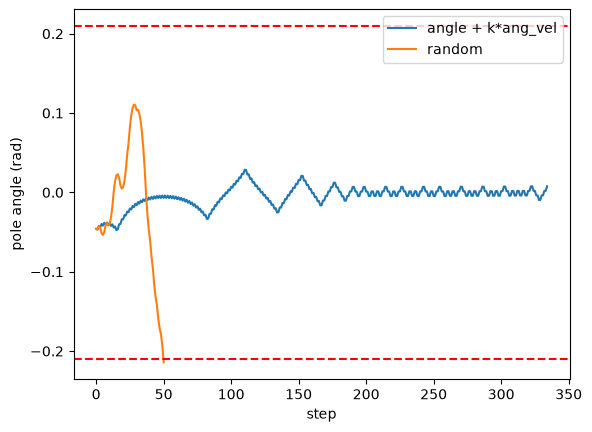

In [10]:
# Plot pole angle vs time for a good and a bad policy
def angle_trace(policy_fn, seed=0):
    env = gym.make("CartPole-v1")
    obs, _ = env.reset(seed=seed)
    angles, done = [obs[2]], False
    while not done:
        obs, _, terminated, truncated, _ = env.step(policy_fn(obs))
        angles.append(obs[2])
        done = terminated or truncated
    env.close()
    return angles

plt.plot(angle_trace(policy_combined), label="angle + k*ang_vel")
plt.plot(angle_trace(random_policy), label="random")
plt.axhline(0.2095, color="r", ls="--")
plt.axhline(-0.2095, color="r", ls="--")
plt.xlabel("step")
plt.ylabel("pole angle (rad)")
plt.legend()
plt.show()

In [11]:
# Q-table size if each variable is discretized into N bins
n_bins = 10  # TODO: try other values
n_states = n_bins ** 4
n_actions = 2
print(f"{n_bins} bins/variable -> {n_states:,} states x {n_actions} actions = {n_states * n_actions:,} Q-values")

10 bins/variable -> 10,000 states x 2 actions = 20,000 Q-values


---
# ▶ NN: NEURAL-NETWORK Q-LEARNING (DQN with ReLU)
**Experiment of the notebook author.** It extends the original CartPole activity above: the hand-written rule `policy(obs) -> action` is replaced by a learned `argmax_a Q(obs, a)`. Everything here is new code; nothing from the OG section or from Bryan's section is edited. All names start with `NN`/`nn_` so the three sections can live in one kernel.
---

## What the OG section taught us, and how it shapes the network

| Finding in OG | Consequence for the NN |
|---|---|
| Angle **and** angular velocity are both needed (Experiments C, Part 3: 40.9 / 198.7 vs 491.7) | the network gets all 4 state variables; it has to rediscover `angle + K·ang_vel` by itself |
| Return = steps survived, cap 500; truncation is not failure (Experiment D) | the success metric is greedy **episode return**, not TD loss; the target masks `terminated` only |
| The best rule scores 491.7 (K=1), about 500 with K≈0.25–0.5 | that is the number the network has to match |
| Returns are noisy and capped at 500 (std 36 came from one 334-step episode) | validation uses 10 fixed episodes; the final score uses 50 **fresh** episodes nobody tuned on |
| Failure by cart drift takes hundreds of steps (angular-velocity-only policy) | γ has to stay high; we test γ = 0.95 / 0.98 below and both are worse than 0.99 |

## The agent

| Piece | Choice |
|---|---|
| Q-network | 4 → 128 → 128 → 2, **ReLU** after both hidden layers, linear output (17,410 parameters) |
| Exploration | ε-greedy, ε: 1.0 → 0.05 over 5,000 steps |
| Replay | ring buffer, 20,000 transitions, batches of 64 |
| Loss / optimiser | Huber loss, Adam (lr 5e-4), gradient clipping at 10 |
| Target | `r + γ(1 − terminated)·Q_target(s', a*)`, γ = 0.99 |
| **Double DQN** (new) | `a*` is chosen by the **online** net and **scored** by the target net |
| **Soft target** (new) | target ← (1 − τ)·target + τ·online after every update, τ = 0.02 (instead of a hard copy every 300 steps) |
| **Patience** (new) | greedy return on 10 validation episodes every 1,000 steps; stop after P checks without improvement; restore the best weights. A **grace period** (`grace`) keeps early plateaus from triggering the stop (added after N2a showed why) |
| `device` | `"cpu"` or `"cuda"`, compared in the timing section |

Every run records its own wall-clock time (`time.perf_counter`); the time ledger at the end lists every code cell.

In [11]:
import os, copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

NN_DEFAULT_THREADS = torch.get_num_threads()    # what torch would use on its own
torch.set_num_threads(1)                        # a 128-unit MLP gains nothing from threads (measured below)

class NNQNetwork(nn.Module):
    """Q(s, .): 4 state variables in -> 2 Q-values out, ReLU between the layers, linear output."""
    def __init__(self, n_hidden=128, dropout=0.0):
        super().__init__()
        layers = [nn.Linear(4, n_hidden), nn.ReLU()]
        if dropout: layers.append(nn.Dropout(dropout))
        layers += [nn.Linear(n_hidden, n_hidden), nn.ReLU()]
        if dropout: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(n_hidden, 2))                  # no activation: a Q-value can be any real number
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class NNReplayBuffer:
    """Ring buffer of the last `capacity` transitions (s, a, r, s', terminated)."""
    def __init__(self, capacity):
        self.s  = np.zeros((capacity, 4), np.float32); self.s2 = np.zeros((capacity, 4), np.float32)
        self.a  = np.zeros(capacity, np.int64); self.r = np.zeros(capacity, np.float32); self.d = np.zeros(capacity, np.float32)
        self.cap, self.n, self.i = capacity, 0, 0

    def add(self, s, a, r, s2, d):
        self.s[self.i], self.a[self.i], self.r[self.i], self.s2[self.i], self.d[self.i] = s, a, r, s2, d
        self.i = (self.i + 1) % self.cap
        self.n = min(self.n + 1, self.cap)

    def sample(self, k, rng):
        idx = rng.integers(0, self.n, k)
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.d[idx]


def nn_run_policy(q, seeds):
    """Mean return of the greedy policy argmax_a Q(s, a) on the given start seeds (eval mode: no dropout)."""
    q = copy.deepcopy(q).cpu().eval()
    env, rets = gym.make("CartPole-v1"), []
    for sd in seeds:
        o, _ = env.reset(seed=int(sd)); tot, done = 0.0, False
        while not done:
            with torch.no_grad():
                a = int(q(torch.as_tensor(o, dtype=torch.float32)).argmax())
            o, r, te, tr, _ = env.step(a); tot += r; done = te or tr
        rets.append(tot)
    env.close()
    return float(np.mean(rets))


class PatienceStopper:
    """Call update(score, step) once per validation. A score is an improvement only if it beats the best so far
    by more than min_delta. After `patience` validations in a row without improvement it says stop.
    GRACE PERIOD: validations before step `start_from` can still improve the best score (and are checkpointed)
    but never count as "no improvement", so early plateaus cannot stop training. patience=None never stops."""
    def __init__(self, patience, min_delta=1.0, start_from=0):
        self.patience, self.min_delta, self.start_from = patience, min_delta, start_from
        self.best, self.bad = -float("inf"), 0

    def update(self, score, step=None):
        improved = score > self.best + self.min_delta
        if improved:
            self.best, self.bad = score, 0
        elif step is None or step >= self.start_from:
            self.bad += 1
        return improved, (self.patience is not None and self.bad >= self.patience)


def nn_sync(device):
    """CUDA is asynchronous: wait for the GPU before reading the clock."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def train_nn(seed=0, steps=30_000, device="cpu", hidden=128, gamma=0.99, lr=5e-4, batch=64, buffer=20_000,
             target_sync=300, tau=None, double=False, dropout=0.0,
             eps_end=0.05, eps_decay=5_000, learn_start=1_000, clip=10.0,
             patience=None, grace=0, eval_every=1_000, val_episodes=10, min_delta=1.0,   # PATIENCE: optional, off by default
             diagnostics=False):
    torch.set_num_threads(1)
    device = torch.device(device)
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    q, q_t = NNQNetwork(hidden, dropout).to(device), NNQNetwork(hidden, dropout).to(device)
    q_t.load_state_dict(q.state_dict()); q_t.eval()
    opt, buf = torch.optim.Adam(q.parameters(), lr=lr), NNReplayBuffer(buffer)
    val_seeds = range(10_000, 10_000 + val_episodes)               # validation episodes (never used as test)

    stopper = PatienceStopper(patience, min_delta, grace)          # PATIENCE (+ grace period)
    best_state, best_step, stopped_step, evals, diag = None, 0, None, [], []   # PATIENCE: (step, validation score)
    t_eval, loss_acc, loss_n = 0.0, 0.0, 0
    o, _ = env.reset(seed=1_000 + seed)                             # training starts differ from validation/test seeds
    nn_sync(device); t0 = time.perf_counter()
    for step in range(1, steps + 1):
        eps = max(eps_end, 1.0 - (1.0 - eps_end) * step / eps_decay)
        if rng.random() < eps:                                      # explore
            a = int(rng.integers(2))
        else:                                                       # exploit: argmax_a Q(s, a)
            q.eval()
            with torch.no_grad():
                a = int(q(torch.as_tensor(o, dtype=torch.float32, device=device)).argmax())
            q.train()
        o2, r, te, tr, _ = env.step(a)
        buf.add(o, a, r, o2, float(te))                             # store `terminated` only, not `truncated`
        o = o2
        if te or tr:
            o, _ = env.reset()

        if buf.n >= learn_start:
            s, a_, r_, s2, d = (torch.as_tensor(x, device=device) for x in buf.sample(batch, rng))
            q_sa = q(s).gather(1, a_.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                if double:                                          # DOUBLE DQN: online net picks, target net scores
                    nxt = q_t(s2).gather(1, q(s2).argmax(1, keepdim=True)).squeeze(1)
                else:                                               # plain DQN: target net picks and scores
                    nxt = q_t(s2).max(1).values
                y = r_ + gamma * (1 - d) * nxt
            loss = F.smooth_l1_loss(q_sa, y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), clip)
            opt.step()
            loss_acc += float(loss) if diagnostics else 0.0; loss_n += 1
            if tau is not None:                                     # SOFT target: blend a little every step
                with torch.no_grad():
                    for p, pt in zip(q.parameters(), q_t.parameters()):
                        pt.mul_(1 - tau).add_(p, alpha=tau)
            elif step % target_sync == 0:                           # HARD target: copy every `target_sync` steps
                q_t.load_state_dict(q.state_dict())

        # ---- PATIENCE: every `eval_every` steps score the greedy policy and decide -------------------
        if step % eval_every == 0:
            nn_sync(device); te0 = time.perf_counter()
            score = nn_run_policy(q, val_seeds)                     # validation return
            t_eval += time.perf_counter() - te0
            evals.append((step, score))
            if diagnostics:
                m = min(buf.n, 2000); idx = (buf.i - 1 - np.arange(m)) % buf.cap
                with torch.no_grad():
                    q.eval(); mq = float(q(torch.as_tensor(buf.s[idx], device=device)).max(1).values.mean()); q.train()
                diag.append(dict(step=step, val=score, loss=loss_acc / max(loss_n, 1), mean_maxq=mq,
                                 term_frac=float(buf.d[:buf.n].mean())))
                loss_acc, loss_n = 0.0, 0
            improved, stop = stopper.update(score, step)
            if improved:                                            # new best -> keep a checkpoint
                best_step, best_state = step, copy.deepcopy(q.state_dict())
            if stop:                                                # patience exhausted -> early stop
                stopped_step = step
                break
    nn_sync(device); seconds = time.perf_counter() - t0
    env.close()

    q_last = copy.deepcopy(q).cpu().eval()                          # weights at the last step
    if best_state is not None:                                      # PATIENCE: return the BEST weights seen
        q.load_state_dict(best_state)
    q = q.cpu().eval()
    return dict(q=q, q_last=q_last, evals=evals, diag=diag, best_val=stopper.best, best_step=best_step,
                stopped_step=stopped_step, steps_used=step, seconds=seconds, eval_seconds=t_eval,
                train_seconds=seconds - t_eval)

print("torch", torch.__version__, "| gymnasium", gym.__version__, "| logical cores:", os.cpu_count(),
      "| torch default threads:", NN_DEFAULT_THREADS)

torch 2.11.0+cu128 | gymnasium 1.3.0 | logical cores: 8 | torch default threads: 4


In [12]:
# Quick look: the ReLU network, then a short training run with the recipe (time is printed)
q0 = NNQNetwork()
print(q0)
print(f"{sum(p.numel() for p in q0.parameters()):,} parameters (the 10-bin Q-table of OG had {n_states * n_actions:,} entries, only for discretised states)")
_o, _ = gym.make("CartPole-v1").reset(seed=SEED)
print("obs  ->", _o); print("Q(s) ->", q0(torch.as_tensor(_o)).detach().numpy(), "(untrained: Q(s, left), Q(s, right))")

t0 = time.perf_counter()
smoke = train_nn(seed=SEED, steps=3_000, double=True, tau=0.02, eval_every=1_000)
print(f"\n3,000 steps in {smoke['seconds']:.1f} s ({smoke['eval_seconds']:.1f} s of it validation)")
print("validation return every 1,000 steps:", [round(s) for _, s in smoke["evals"]])
print("same evaluation as OG Part 3 (20 episodes, seeds 0-19):", evaluate_policy(lambda ob: int(smoke["q"](torch.as_tensor(ob, dtype=torch.float32)).argmax())))

NNQNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
17,410 parameters (the 10-bin Q-table of OG had 20,000 entries, only for discretised states)
obs  -> [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Q(s) -> [0.08080166 0.13610002] (untrained: Q(s, left), Q(s, right))



3,000 steps in 4.0 s (0.6 s of it validation)
validation return every 1,000 steps: [75, 288, 215]


same evaluation as OG Part 3 (20 episodes, seeds 0-19): (283.9, 20.82282401596863)


In [13]:
# Self-check (CPU, about 30 s): ReLU, the stopper, double-vs-plain difference, patience is an exact prefix, best weights returned
assert sum(isinstance(m, nn.ReLU) for m in NNQNetwork().modules()) == 2, "ReLU after both hidden layers"
assert isinstance(list(NNQNetwork().net)[-1], nn.Linear), "linear output layer"

st = PatienceStopper(patience=3, min_delta=1.0)
for score, expected in [(10, (True, False)), (20, (True, False)), (20, (False, False)),
                        (20.5, (False, False)), (19, (False, True))]:      # 3rd bad validation -> stop
    assert st.update(score) == expected, (score, expected)
assert st.best == 20 and st.bad == 3 and PatienceStopper(None).update(0.0)[1] is False
g = PatienceStopper(patience=2, min_delta=1.0, start_from=3000)             # grace period: nothing counts as "bad" before step 3000
assert [g.update(s, st_) for s, st_ in [(10, 1000), (5, 2000), (5, 2500)]] == [(True, False), (False, False), (False, False)] and g.bad == 0
assert g.update(5, 3000) == (False, False) and g.update(5, 4000) == (False, True), "counting starts at start_from"
assert PatienceStopper(patience=2, start_from=3000).update(50, 1000) == (True, False), "improvements inside the grace period still count"

KW = dict(steps=4_000, learn_start=500, eval_every=500, double=True, tau=0.02)
t0 = time.perf_counter()
full, pat = train_nn(**KW), train_nn(**KW, patience=1)
gr = train_nn(**KW, patience=1, grace=2_000)
assert gr["steps_used"] >= 2_000 and gr["evals"] == full["evals"][:len(gr["evals"])], "grace period delays the stop"
assert pat["stopped_step"] is not None and pat["steps_used"] < 4_000, "patience=1 should stop early"
assert pat["evals"] == full["evals"][:len(pat["evals"])], "a patience run must follow the full run until it stops"
assert nn_run_policy(pat["q"], range(10_000, 10_010)) == pat["best_val"], "the returned weights are the best checkpoint"
plain = train_nn(steps=1_500, learn_start=500, eval_every=500)
dbl   = train_nn(steps=1_500, learn_start=500, eval_every=500, double=True)
assert not all(torch.equal(a, b) for a, b in zip(plain["q"].state_dict().values(), dbl["q"].state_dict().values())), "double DQN must change the update"
print(f"NN: all checks passed in {time.perf_counter()-t0:.0f} s (patience=1 stopped at step {pat['stopped_step']}, best checkpoint at step {pat['best_step']})")

NN: all checks passed in 17 s (patience=1 stopped at step 1000, best checkpoint at step 500)


### N0: why does plain DQN collapse? (diagnosis, with time)
The plain recipe (hard target copy every 300 steps, no double Q) reaches 500 on the validation episodes and then falls back to 100–300. Before changing anything we look at what the network does during training: the loss, the **mean of max-Q** over recent states, and the **fraction of failure transitions** in the replay buffer.

3 plain-DQN runs of 12,000 steps in parallel: 33 s wall | per run: [27, 26, 27] s

seed 0:  step   val   loss  mean maxQ  failure transitions in buffer
            2000   276  0.046       3.9         3.25%
            4000   443  0.126      10.5         2.13%
            6000   182  0.148      15.8         1.50%
            8000   131  0.166      21.0         1.26%
           10000   155  0.186      25.8         1.15%
           12000   139  0.202      30.4         1.08%
seed 1:  step   val   loss  mean maxQ  failure transitions in buffer
            2000    95  0.052       4.0         4.50%
            4000   170  0.120      10.9         2.82%
            6000   209  0.160      15.7         2.03%
            8000   184  0.185      21.2         1.65%
           10000   478  0.206      26.4         1.43%
           12000   132  0.200      34.2         1.27%
seed 2:  step   val   loss  mean maxQ  failure transitions in buffer
            2000   489  0.049       3.9         4.30%
        

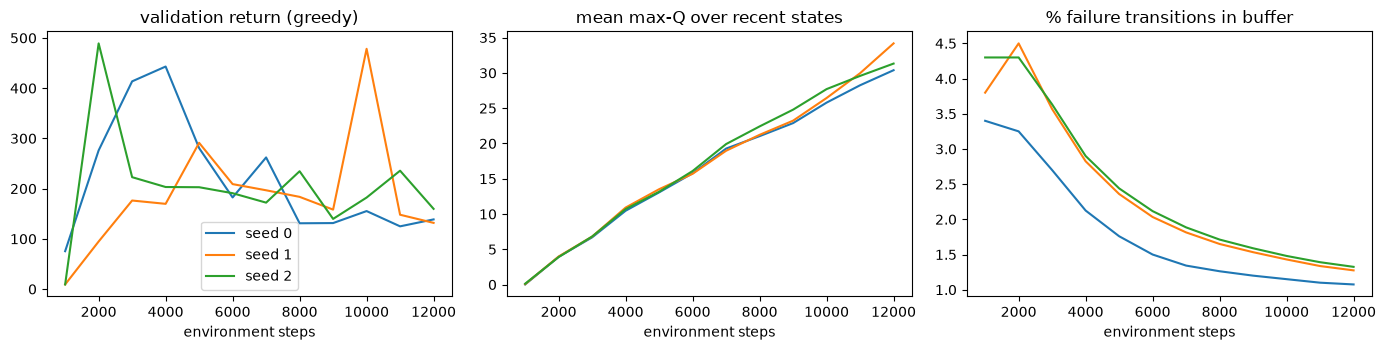

In [14]:
def nn_diag_job(seed):
    out = train_nn(seed=seed, steps=12_000, diagnostics=True)
    return dict(seed=seed, diag=out["diag"], seconds=out["seconds"])

t0 = time.perf_counter()
diag_runs = Parallel(n_jobs=3)(delayed(nn_diag_job)(s) for s in (0, 1, 2))
print(f"3 plain-DQN runs of 12,000 steps in parallel: {time.perf_counter()-t0:.0f} s wall | per run: {[round(r['seconds']) for r in diag_runs]} s\n")
for r in diag_runs:
    print(f"seed {r['seed']}:  step   val   loss  mean maxQ  failure transitions in buffer")
    for d in r["diag"][1::2]:
        print(f"          {d['step']:6d} {d['val']:5.0f} {d['loss']:6.3f} {d['mean_maxq']:9.1f} {100*d['term_frac']:12.2f}%")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for r in diag_runs:
    st = [d["step"] for d in r["diag"]]
    ax[0].plot(st, [d["val"] for d in r["diag"]], label=f"seed {r['seed']}")
    ax[1].plot(st, [d["mean_maxq"] for d in r["diag"]])
    ax[2].plot(st, [100 * d["term_frac"] for d in r["diag"]])
ax[0].set_title("validation return (greedy)"); ax[1].set_title("mean max-Q over recent states"); ax[2].set_title("% failure transitions in buffer")
for a_ in ax: a_.set_xlabel("environment steps")
ax[0].legend(); plt.tight_layout(); plt.show()

*N0 findings (this run: 3 plain-DQN trainings × 12,000 steps, 33 s wall):*

- **The greedy policy is unstable between checks.** Validation return on seed 0 went 276 → 443 → 182 → 131 → 155 → 139; on seed 1 it reached 478 at step 10,000 and was 132 at step 12,000; on seed 2 it was 489 at step 2,000 and 160 at step 12,000. Weights at an arbitrary step can be much worse than weights a few thousand steps earlier, which is why a best checkpoint is kept.
- **The value scale is still growing.** Mean max-Q over recent states rose steadily on all three seeds, from about 4 at step 2,000 to 30–34 at step 12,000, with no sign of levelling off; the loss also kept rising (0.05 → 0.20–0.24). The network is still learning how big the values are while the action choice depends on a small difference between two large numbers. This is a working explanation consistent with the swings, **not** something tested by an intervention here.
- **Failure transitions get rare in the replay buffer:** 3.3–4.5% at step 2,000 against 1.1–1.3% at step 12,000, so the network sees less and less evidence about what failing looks like.


### N1: which stabiliser fixes it? (development seeds)
Each configuration trained for 30,000 steps with the **development** training seeds, and was scored on 50 **development** test episodes (seeds 20,000–20,049). Neither the final training seeds (300–304) nor the final test seeds (30,000–30,049) were used here. Two numbers per run: the test return of the **restored best checkpoint** and of the **last weights**. These tables were recorded by `sweep_resumable.py` with exactly the code of `train_nn` (a script run, not a cell run, because 40+ trainings do not fit in a lab session); the next cell prints them and `train_nn` reproduces any row.


round 1 (training seeds 100-102): 30,000 steps, test = 50 development episodes (seeds 20,000-20,049)
config                                 best-ckpt test by seed   mean          last-weights test by seed   mean  s/run
base                                          [446, 500, 477]  474.3                    [156, 500, 130]  262.1     94
double                                        [496, 210, 500]  402.0                    [500, 239, 500]  413.1    100
gamma0.95                                     [261, 370, 495]  375.4                    [144, 126, 120]  130.1     90
gamma0.98                                     [500, 225, 244]  323.0                    [355, 175, 119]  216.3     90
soft tau0.005                                 [500, 496, 236]  410.6                    [487, 500, 160]  382.4     92
double+tau0.01                                [500, 500, 500]  500.0                    [500, 500, 500]  500.0    106
double+lr1e-3                                 [415, 500, 260]  391.9    

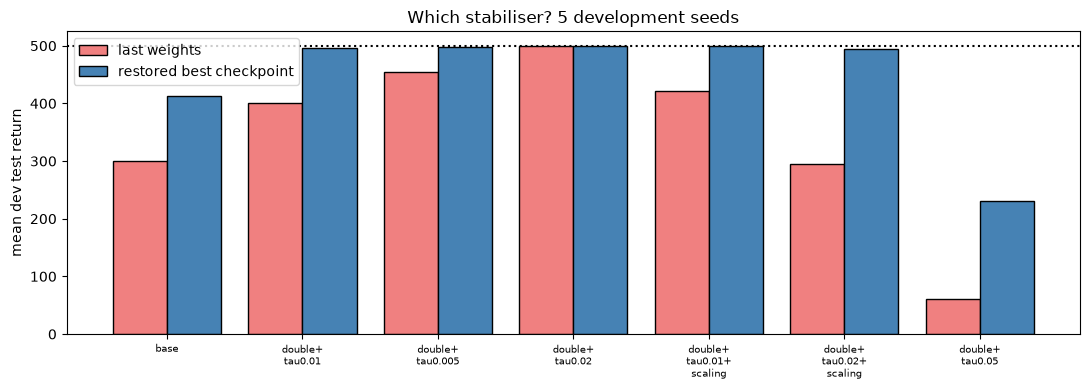

In [15]:
# Development sweeps recorded by sweep_resumable.py (same train_nn code). best = restored best checkpoint, last = last weights
NN_DEV = {
 "round 1 (training seeds 100-102)": {
  "base": {
   "best": [
    445.8,
    500.0,
    477.0
   ],
   "last": [
    156.3,
    500.0,
    129.9
   ],
   "secs": [
    93,
    94,
    95
   ]
  },
  "double": {
   "best": [
    495.7,
    210.2,
    500.0
   ],
   "last": [
    500.0,
    239.2,
    500.0
   ],
   "secs": [
    104,
    96,
    100
   ]
  },
  "gamma0.95": {
   "best": [
    261.0,
    369.7,
    495.4
   ],
   "last": [
    144.4,
    125.7,
    120.3
   ],
   "secs": [
    89,
    90,
    91
   ]
  },
  "gamma0.98": {
   "best": [
    500.0,
    224.9,
    244.2
   ],
   "last": [
    355.2,
    175.0,
    118.8
   ],
   "secs": [
    93,
    88,
    88
   ]
  },
  "soft tau0.005": {
   "best": [
    500.0,
    495.8,
    236.1
   ],
   "last": [
    487.0,
    500.0,
    160.1
   ],
   "secs": [
    92,
    93,
    90
   ]
  },
  "double+tau0.01": {
   "best": [
    500.0,
    500.0,
    500.0
   ],
   "last": [
    500.0,
    500.0,
    500.0
   ],
   "secs": [
    104,
    110,
    104
   ]
  },
  "double+lr1e-3": {
   "best": [
    415.4,
    500.0,
    260.4
   ],
   "last": [
    379.4,
    108.8,
    323.5
   ],
   "secs": [
    135,
    141,
    134
   ]
  },
  "input scaling": {
   "best": [
    500.0,
    497.7,
    496.8
   ],
   "last": [
    16.1,
    500.0,
    122.7
   ],
   "secs": [
    133,
    131,
    127
   ]
  },
  "buffer100k": {
   "best": [
    445.8,
    264.1,
    500.0
   ],
   "last": [
    147.6,
    215.7,
    146.8
   ],
   "secs": [
    91,
    91,
    91
   ]
  },
  "combo(dbl,tau,g.98,sc)": {
   "best": [
    500.0,
    500.0,
    500.0
   ],
   "last": [
    97.4,
    500.0,
    494.8
   ],
   "secs": [
    100,
    98,
    95
   ]
  }
 },
 "round 2 (training seeds 200-204)": {
  "base": {
   "best": [
    500.0,
    318.9,
    500.0,
    247.4,
    500.0
   ],
   "last": [
    192.9,
    161.7,
    500.0,
    180.3,
    469.4
   ],
   "secs": [
    95,
    93,
    94,
    93,
    94
   ]
  },
  "double+tau0.01": {
   "best": [
    500.0,
    497.3,
    500.0,
    486.8,
    493.6
   ],
   "last": [
    287.9,
    283.7,
    500.0,
    500.0,
    435.1
   ],
   "secs": [
    109,
    116,
    117,
    116,
    113
   ]
  },
  "double+tau0.005": {
   "best": [
    500.0,
    500.0,
    494.3,
    500.0,
    497.2
   ],
   "last": [
    500.0,
    500.0,
    325.9,
    500.0,
    448.1
   ],
   "secs": [
    113,
    120,
    113,
    116,
    115
   ]
  },
  "double+tau0.02": {
   "best": [
    500.0,
    500.0,
    500.0,
    500.0,
    500.0
   ],
   "last": [
    500.0,
    500.0,
    500.0,
    500.0,
    500.0
   ],
   "secs": [
    122,
    111,
    117,
    106,
    110
   ]
  },
  "double+tau0.01+scaling": {
   "best": [
    500.0,
    500.0,
    500.0,
    500.0,
    499.2
   ],
   "last": [
    500.0,
    103.6,
    500.0,
    500.0,
    500.0
   ],
   "secs": [
    110,
    108,
    117,
    120,
    122
   ]
  },
  "double+tau0.02+scaling": {
   "best": [
    500.0,
    500.0,
    499.6,
    469.3,
    500.0
   ],
   "last": [
    500.0,
    108.2,
    500.0,
    86.6,
    278.1
   ],
   "secs": [
    216,
    162,
    173,
    172,
    168
   ]
  },
  "double+tau0.05": {
   "best": [
    500.0,
    286.4,
    9.4,
    194.5,
    164.7
   ],
   "last": [
    266.6,
    9.4,
    9.3,
    9.4,
    9.3
   ],
   "secs": [
    212,
    191,
    193,
    209,
    198
   ]
  }
 }
}

for rnd, cfgs in NN_DEV.items():
    print(f"\n{rnd}: 30,000 steps, test = 50 development episodes (seeds 20,000-20,049)")
    print(f"{'config':26s} {'best-ckpt test by seed':>34s} {'mean':>6s} {'last-weights test by seed':>34s} {'mean':>6s} {'s/run':>6s}")
    for n, e in cfgs.items():
        print(f"{n:26s} {str([round(x) for x in e['best']]):>34s} {np.mean(e['best']):6.1f} {str([round(x) for x in e['last']]):>34s} {np.mean(e['last']):6.1f} {np.mean(e['secs']):6.0f}")
cfgs = NN_DEV["round 2 (training seeds 200-204)"]; names = list(cfgs); x = np.arange(len(names))
plt.figure(figsize=(11, 4)); plt.bar(x - 0.2, [np.mean(cfgs[n]["last"]) for n in names], 0.4, label="last weights", color="lightcoral", edgecolor="k")
plt.bar(x + 0.2, [np.mean(cfgs[n]["best"]) for n in names], 0.4, label="restored best checkpoint", color="steelblue", edgecolor="k")
plt.xticks(x, [n.replace("+", "+\n") for n in names], fontsize=7); plt.axhline(500, ls=":", c="k"); plt.ylabel("mean dev test return"); plt.title("Which stabiliser? 5 development seeds"); plt.legend(); plt.tight_layout(); plt.show()

*N1 findings (development seeds only; 30,000 steps, 50 development test episodes):*

- **Double DQN with a soft target update was the combination that stabilised training.** On five development seeds, `double + τ = 0.02` scored **500 on every seed, for both the restored best checkpoint and the last weights**; plain DQN scored 413.3 (best checkpoint) and 300.9 (last weights) on the same seeds. `double + τ = 0.01` and `0.005` were close behind (495.5 / 401.3 and 498.3 / 454.8).
- **Each ingredient alone was not enough.** Double DQN alone: 402.0 best / 413.1 last (3 seeds); a soft target alone (τ = 0.005): 410.6 / 382.4. The gain appeared when they were combined.
- **Things that did not help:** a lower discount (γ = 0.95: 375.4 / 130.1; γ = 0.98: 323.0 / 216.3 against 474.3 / 262.1 for γ = 0.99 on the same three seeds), which fits the OG finding that a cart drifting off the track fails *hundreds* of steps after the mistake and so needs a long horizon; a larger buffer (100,000: 403.3 / 170.0); a higher learning rate on top of double DQN (1e-3: 391.9 / 270.6).
- **Input scaling** raised the restored-best score (498.2) but not the last weights (212.9), i.e. it did not remove the collapses.
- **τ is a setting with a cliff next to it.** Scores improved from τ = 0.005 to 0.01 to 0.02, but **τ = 0.05 collapsed** (231.0 best, 60.8 last; four of the five last-weight networks scored the dead value ≈ 9). τ = 0.02 is chosen *because* it won here, which is exactly why it has to be re-tested on seeds nobody tuned on (N2).
- **Caveat on how much to trust this table.** About a dozen configurations were compared on 3–5 seeds, so the winner is partly lucky (winner's curse). The fresh-seed result in N2 is the honest size of the gain, and it is smaller.
- **Timing:** each 30,000-step run took roughly 90–140 s (6 runs in parallel, so contended).

### N2a: what went wrong the first time (seeds 300–304, recorded)
The first final comparison used training seeds **300–304** and test seeds 30,000–30,049, one change at a time. It did **not** show the recipe winning, and the reasons are the whole point of the next experiment. Per-seed numbers below were recorded by `sweep_resumable.py` (same `train_nn` code); the improved-recipe and dropout rows are the aggregates reported by the parallel walkthrough session for the same seeds and were not re-run here.

In [16]:
# Recorded on training seeds 300-304, test = 50 episodes (seeds 30,000-30,049), 30,000-step budget. last = last weights, best = restored best checkpoint
NN_STORY = {'plain DQN, last weights': {'test': [360.1, 500.0, 500.0, 500.0, 500.0], 'mean': 472.0, 'steps': 30000},
 'plain DQN, restored best checkpoint': {'test': [500.0, 500.0, 500.0, 500.0, 500.0],
                                         'mean': 500.0,
                                         'steps': 30000},
 'recipe, last weights (aggregate, reported)': {'test': None, 'mean': 401.8, 'steps': 30000},
 'recipe + dropout 0.1, last weights (aggregate, reported)': {'test': None, 'mean': 343.8, 'steps': 30000},
 'recipe + patience P=3 (no grace), best checkpoint': {'test': [212.9, 169.5, 346.4, 199.3, 356.4],
                                                       'mean': 256.9,
                                                       'steps': 7400},
 'recipe + patience P=5 (no grace), best checkpoint': {'test': [212.9, 169.5, 346.4, 237.6, 356.4],
                                                       'mean': 264.6,
                                                       'steps': 10200},
 'recipe + patience P=10 (no grace), best checkpoint': {'test': [500.0, 494.4, 500.0, 500.0, 500.0],
                                                        'mean': 498.9,
                                                        'steps': 23600}}
print(f"{'run':46s} {'test by seed (300-304)':>28s} {'mean':>6s} {'steps used':>11s}")
for k, e in NN_STORY.items():
    per = str([round(x) for x in e['test']]) if e.get('test') else '(aggregate only)'
    print(f"{k:46s} {per:>28s} {e['mean']:6.1f} {e['steps']:>11}")
print("\n=> the recipe reaches 500 on 4 of 5 seeds, but seed 304 collapses to ~9 after four validation scores of 500: the LAST weights can be dead.")
print("=> patience P=3 and P=5 stopped INSIDE the plateau that precedes the breakthrough (at 11-19k steps): 257-265. P=10 waited long enough: 499 (best checkpoint).")
print("=> dropout 0.1 did not help (343.8); plain DQN's last weights were already good on these seeds.")

run                                                  test by seed (300-304)   mean  steps used
plain DQN, last weights                           [360, 500, 500, 500, 500]  472.0       30000
plain DQN, restored best checkpoint               [500, 500, 500, 500, 500]  500.0       30000
recipe, last weights (aggregate, reported)                 (aggregate only)  401.8       30000
recipe + dropout 0.1, last weights (aggregate, reported)             (aggregate only)  343.8       30000
recipe + patience P=3 (no grace), best checkpoint    [213, 170, 346, 199, 356]  256.9        7400
recipe + patience P=5 (no grace), best checkpoint    [213, 170, 346, 238, 356]  264.6       10200
recipe + patience P=10 (no grace), best checkpoint    [500, 494, 500, 500, 500]  498.9       23600

=> the recipe reaches 500 on 4 of 5 seeds, but seed 304 collapses to ~9 after four validation scores of 500: the LAST weights can be dead.
=> patience P=3 and P=5 stopped INSIDE the plateau that precedes the breakthroug

---
# ▶ NN EXPERIMENT N2: PLAIN vs RECIPE vs RECIPE + GRACE-PERIOD PATIENCE
---
**The fix suggested by N2a, tested on seeds nobody has looked at.** Training seeds **400–404**, test = 50 greedy episodes with seeds **40,000–40,049**, 30,000-step budget, `train_nn` for every row. The grace period (15,000 steps) is a design decision taken *because* of what 300–304 showed; 400–404 are fresh, so this is the clean test of it.

| Run | Change | Patience |
|---|---|---|
| **N0** plain DQN | hard target copy every 300 steps, plain max | OFF: reports the **last** weights and the **restored best** weights of the same run |
| **N1** recipe | + double DQN + soft target τ = 0.02 | OFF: last / restored best |
| **N2** recipe + grace patience | N1 with early stopping: **no stop before step 15,000**, then stop after P = 10 validations without improvement, return the best weights | ON |

**Every run records its wall-clock time.** With 8 runs in parallel on 4 physical cores the per-run seconds include contention; the comparison section times batches properly.

In [17]:
NN_FINAL_SEEDS = (400, 401, 402, 403, 404)
NN_TEST_SEEDS  = range(40_000, 40_050)
NN_GRACE, NN_PATIENCE = 15_000, 10

NN_FINAL_RUNS = {                                    # label -> kwargs of train_nn
    "N0 plain DQN":                       dict(),                                              # patience OFF
    "N1 recipe (double + soft target)":   dict(double=True, tau=0.02),                          # patience OFF
    "N2 recipe + grace patience":         dict(double=True, tau=0.02, patience=NN_PATIENCE, grace=NN_GRACE),   # <- patience ON
}

def nn_final_job(label, cfg, seed):
    out = train_nn(seed=seed, steps=30_000, **cfg)
    return dict(label=label, seed=seed, best=nn_run_policy(out["q"], NN_TEST_SEEDS), last=nn_run_policy(out["q_last"], NN_TEST_SEEDS),
                steps_used=out["steps_used"], best_step=out["best_step"], stopped_step=out["stopped_step"],
                seconds=out["seconds"], eval_seconds=out["eval_seconds"], evals=out["evals"], best_val=out["best_val"])

t0 = time.perf_counter()
nn_jobs = [(lb, c, s) for lb, c in NN_FINAL_RUNS.items() for s in NN_FINAL_SEEDS]
nn_final = Parallel(n_jobs=8)(delayed(nn_final_job)(*j) for j in nn_jobs)
NN_FINAL_WALL = time.perf_counter() - t0
print(f"{len(nn_jobs)} trainings, 8 in parallel: {NN_FINAL_WALL:.0f} s wall ({NN_FINAL_WALL/60:.1f} min); sum of run times {sum(r['seconds'] for r in nn_final):.0f} s\n")

print(f"{'run':36s} {'weights':>9s} {'test by seed (400-404)':>28s} {'mean ± std':>14s} {'steps used':>11s} {'s / run':>8s}")
nn_table = {}
for lb in NN_FINAL_RUNS:
    rs = [r for r in nn_final if r["label"] == lb]
    for key, nm in ((("last", "last"), ("best", "best ckpt")) if "grace" not in lb else (("best", "best ckpt"),)):
        t = np.array([r[key] for r in rs]); used = np.mean([r["steps_used"] for r in rs]); secs = np.mean([r["seconds"] for r in rs])
        nn_table[(lb, key)] = (t, used, secs)
        print(f"{lb:36s} {nm:>9s} {str([round(x) for x in t]):>28s} {t.mean():7.1f} ±{t.std():5.1f} {used:11.0f} {secs:8.0f}")
print("\nOG reference on its own protocol: rule angle + 1.0*ang_vel = 491.7 ± 36.2 (seeds 0-19)")

15 trainings, 8 in parallel: 267 s wall (4.4 min); sum of run times 1692 s

run                                    weights       test by seed (400-404)     mean ± std  steps used  s / run
N0 plain DQN                              last     [191, 154, 180, 70, 147]   148.4 ± 42.4       30000       99
N0 plain DQN                         best ckpt    [283, 500, 500, 254, 296]   366.7 ±109.7       30000       99
N1 recipe (double + soft target)          last        [9, 9, 500, 500, 500]   303.7 ±240.4       30000      125
N1 recipe (double + soft target)     best ckpt    [500, 408, 500, 500, 493]   480.3 ± 36.0       30000      125
N2 recipe + grace patience           best ckpt    [500, 408, 500, 500, 493]   480.3 ± 36.0       24200      114

OG reference on its own protocol: rule angle + 1.0*ang_vel = 491.7 ± 36.2 (seeds 0-19)


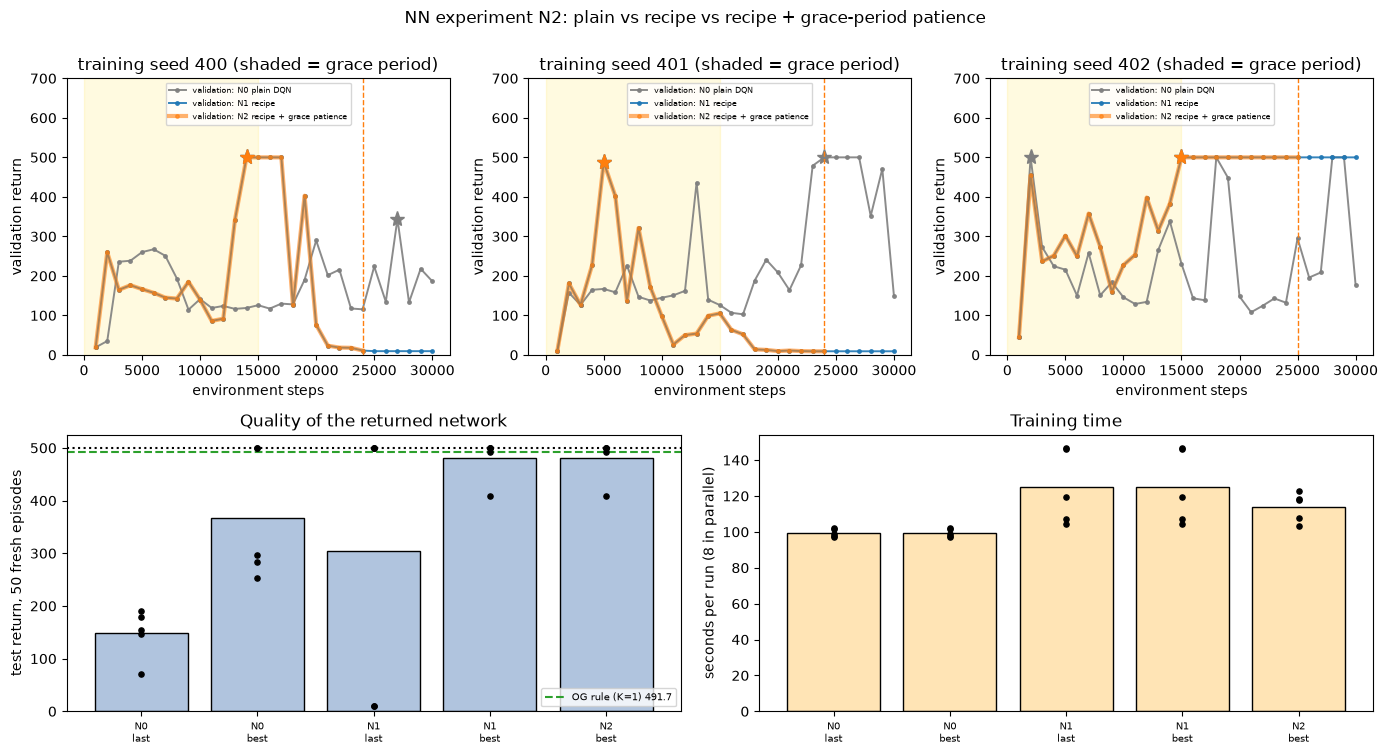

In [18]:
fig = plt.figure(figsize=(14, 7.5)); gs = fig.add_gridspec(2, 6)
for c_, sd in enumerate((400, 401, 402)):
    ax = fig.add_subplot(gs[0, 2*c_:2*c_+2])
    for lb, col in (("N0 plain DQN", "tab:gray"), ("N1 recipe (double + soft target)", "tab:blue"), ("N2 recipe + grace patience", "tab:orange")):
        r = next(r for r in nn_final if r["label"] == lb and r["seed"] == sd); st, sc = zip(*r["evals"])
        ax.plot(st, sc, "-o", ms=2.5, c=col, label=f"validation: {lb.split(' (')[0]}", alpha=0.9 if "N2" not in lb else 0.6, lw=1.4 if "N2" not in lb else 3)
        if r["stopped_step"] is not None: ax.axvline(r["stopped_step"], c=col, ls="--", lw=1)
        ax.plot(r["best_step"], r["best_val"], "*", c=col, ms=11)
    ax.axvspan(0, NN_GRACE, color="gold", alpha=0.12)
    ax.set_title(f"training seed {sd} (shaded = grace period)"); ax.set_xlabel("environment steps"); ax.set_ylabel("validation return"); ax.set_ylim(0, 700)
    ax.legend(fontsize=6, loc="upper center", ncol=1)
rows = [(lb, key) for lb in NN_FINAL_RUNS for key in (("last", "best") if "grace" not in lb else ("best",))]
names = [f"{lb.split(' ')[0]}\n{'last' if k == 'last' else 'best'}" for lb, k in rows]
ax = fig.add_subplot(gs[1, 0:3])
for i, k in enumerate(rows):
    t = nn_table[k][0]; ax.bar(i, t.mean(), color="lightsteelblue", edgecolor="k"); ax.scatter([i]*len(t), t, c="k", s=14, zorder=3)
ax.axhline(500, ls=":", c="k"); ax.axhline(491.7, ls="--", c="tab:green", label="OG rule (K=1) 491.7")
ax.set_xticks(range(len(rows))); ax.set_xticklabels(names, fontsize=7); ax.set_ylabel("test return, 50 fresh episodes"); ax.set_title("Quality of the returned network"); ax.legend(fontsize=7, loc="lower right")
ax = fig.add_subplot(gs[1, 3:6])
for i, k in enumerate(rows):
    sec = [r["seconds"] for r in nn_final if r["label"] == k[0]]; ax.bar(i, np.mean(sec), color="moccasin", edgecolor="k"); ax.scatter([i]*len(sec), sec, c="k", s=14, zorder=3)
ax.set_xticks(range(len(rows))); ax.set_xticklabels(names, fontsize=7); ax.set_ylabel("seconds per run (8 in parallel)"); ax.set_title("Training time")
plt.suptitle("NN experiment N2: plain vs recipe vs recipe + grace-period patience", y=1.0); plt.tight_layout(); plt.show()

*N2 findings (the cell above: seeds 400–404, test seeds 40,000–40,049, 30,000-step budget). It reproduced, seed for seed, the table recorded independently by the parallel walkthrough session, so the runs are deterministic and the numbers are cross-checked.*

| Run | Test by seed (400–404) | Mean ± std | Steps used |
|---|---|---|---|
| N0 plain DQN, last weights | 191 / 154 / 180 / 70 / 147 | 148.4 ± 42.4 | 30,000 |
| N0 plain DQN, restored best checkpoint | 283 / 500 / 500 / 254 / 296 | 366.7 ± 109.7 | 30,000 |
| N1 recipe, last weights | 9 / 9 / 500 / 500 / 500 | 303.7 ± 240.4 | 30,000 |
| N1 recipe, restored best checkpoint | 500 / 408 / 500 / 500 / 493 | 480.3 ± 36.0 | 30,000 |
| N2 recipe + grace patience (15k, P = 10), best | 500 / 408 / 500 / 500 / 493 | 480.3 ± 36.0 | 24,200 |

- **Restoring the best checkpoint is the largest effect:** plain DQN 148.4 → 366.7, recipe 303.7 → 480.3. Two of the five recipe runs ended with a dead last-weights network (score 9) after having scored 500 earlier.
- **Grace-period patience returned exactly the same networks as training to the end, using 19% fewer steps** (24,200 vs 30,000); the runs stopped at steps 24,000–25,000. Without the grace period, patience P = 3 and P = 5 stopped inside the plateau before the breakthrough and scored 257–265 on seeds 300–304 (N2a), while P = 10 scored 499.
- **The recipe adds about +114 on top of checkpoint restoration** (366.7 → 480.3), by seed (recipe vs plain, both with the best checkpoint): better on three seeds (400: 500 vs 283; 403: 500 vs 254; 404: 493 vs 296), tied on one (402: 500 vs 500) and worse on one (401: 408 vs 500). That is far smaller than on the development seeds, as expected from choosing the winner among many settings.
- **Against the rule from OG:** the rule scores 500 on these 50 test episodes (see the comparison), so the best DQN (480.3) is close to it but not above it.
- **Time:** the per-run seconds in the table (mean 99 s plain, 125 s recipe, 114 s grace patience) were measured with 8 runs sharing 4 physical cores, so only the wall time of the whole batch is meaningful: 15 trainings in 267 s (the run times add up to 1,692 s). Clean timings are in the comparison section.
- **Limits:** 5 seeds per arm; the grace period and P = 10 were chosen after seeing seeds 300–304, which is why 400–404 are fresh. Dropout 0.1 (343.8 vs 401.8 without, last weights, seeds 300–304, a single run reported by the parallel session) is weak evidence that it did not help.


---
# ▶ NN EXPERIMENT N3: CPU vs GPU and training time
---
**Question.** Does the GPU make this training faster? Same `train_nn`, `device="cuda"` moves the network, the mini-batches and the target; the environment stays on the CPU. Three timing rules: CUDA is asynchronous (`torch.cuda.synchronize()` before reading the clock), the first CUDA call pays a one-time start-up (we warm up first), and every environment step needs the action back on the CPU. Measurements: (1) the same training on CPU and GPU, (2) where one step's time goes, (3) how the ratio changes with batch size and width. (What patience does to the time is read from the steps and seconds of N2 and from the comparison.)

In [19]:
HAS_GPU = torch.cuda.is_available()
print("CUDA available:", HAS_GPU, "| CUDA build:", torch.version.cuda, "| logical cores:", os.cpu_count(), "| torch default threads:", NN_DEFAULT_THREADS)
if HAS_GPU:
    print("GPU:", torch.cuda.get_device_properties(0).name, f"| {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB")
    t = time.perf_counter(); torch.zeros(1, device="cuda"); torch.cuda.synchronize(); print(f"first CUDA call (one-time start-up): {time.perf_counter()-t:.2f} s")

NN_T_STEPS = 5_000
configs = [("cpu, 1 thread", "cpu", 1), (f"cpu, {NN_DEFAULT_THREADS} threads", "cpu", NN_DEFAULT_THREADS)] + ([("cuda (GPU)", "cuda", 1)] if HAS_GPU else [])
nn_timing, t_all = {}, time.perf_counter()
for name, dev, thr in configs:
    torch.set_num_threads(thr)
    train_nn(device=dev, steps=1_500, learn_start=200, eval_every=10**9)                          # warm-up, not timed
    out = train_nn(device=dev, steps=NN_T_STEPS, double=True, tau=0.02, eval_every=10**9)         # training only, no validation
    nn_timing[name] = dict(seconds=out["seconds"], sps=NN_T_STEPS / out["seconds"], test=nn_run_policy(out["q"], range(30_000, 30_020)))
torch.set_num_threads(1)
base_s = nn_timing["cpu, 1 thread"]["seconds"]
print(f"\n{'device':16s} {'seconds':>8s} {'steps/s':>8s} {'vs cpu 1 thread':>16s}")
for n, r in nn_timing.items(): print(f"{n:16s} {r['seconds']:8.1f} {r['sps']:8.0f} {r['seconds']/base_s:15.2f}x")
print(f"(test returns after only {NN_T_STEPS:,} steps are not a quality comparison: GPU float arithmetic differs slightly, so the trajectories diverge)")
print(f"section time: {time.perf_counter()-t_all:.0f} s")

CUDA available: True | CUDA build: 12.8 | logical cores: 8 | torch default threads: 4
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | 6.0 GiB
first CUDA call (one-time start-up): 0.18 s



device            seconds  steps/s  vs cpu 1 thread
cpu, 1 thread        11.7      429            1.00x
cpu, 4 threads       11.8      424            1.01x
cuda (GPU)           27.0      185            2.32x
(test returns after only 5,000 steps are not a quality comparison: GPU float arithmetic differs slightly, so the trajectories diverge)
section time: 67 s


In [20]:
# (2) Where does the time of ONE training step go?  microseconds per call, measured in isolation
def nn_time_op(fn, device, reps=300):
    for _ in range(20): fn()
    nn_sync(device); t = time.perf_counter()
    for _ in range(reps): fn()
    nn_sync(device); return (time.perf_counter() - t) / reps * 1e6

_buf, _rng = NNReplayBuffer(20_000), np.random.default_rng(0)
for _ in range(5_000): _buf.add(_rng.normal(size=4), int(_rng.integers(2)), 1.0, _rng.normal(size=4), 0.0)

def nn_make_ops(device):
    q = NNQNetwork().to(device); qt = copy.deepcopy(q); opt = torch.optim.Adam(q.parameters(), lr=5e-4)
    batch = [torch.as_tensor(x, device=device) for x in _buf.sample(64, _rng)]
    def act():
        with torch.no_grad(): return int(q(torch.as_tensor(_buf.s[0], device=device)).argmax())
    def sample_and_copy(): return [torch.as_tensor(x, device=device) for x in _buf.sample(64, _rng)]
    def update():
        s, a, r, s2, d = batch
        q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad(): y = r + 0.99 * (1 - d) * qt(s2).gather(1, q(s2).argmax(1, keepdim=True)).squeeze(1)
        loss = F.smooth_l1_loss(q_sa, y); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
    return dict(act=act, sample_and_copy=sample_and_copy, update=update)

t_all = time.perf_counter(); nn_ops = {}
for dev in (["cpu", "cuda"] if HAS_GPU else ["cpu"]):
    d = torch.device(dev); nn_ops[dev] = {k: nn_time_op(f, d) for k, f in nn_make_ops(d).items()}
print(f"{'operation (batch 64, 128 hidden)':34s}" + "".join(f"{dv+' (us)':>12s}" for dv in nn_ops) + (f"{'gpu / cpu':>12s}" if HAS_GPU else ""))
for k in nn_ops["cpu"]:
    print(f"{k:34s}" + "".join(f"{nn_ops[dv][k]:12.0f}" for dv in nn_ops) + (f"{nn_ops['cuda'][k]/nn_ops['cpu'][k]:11.1f}x" if HAS_GPU else ""))
print("sum = one training step".ljust(34) + "".join(f"{sum(nn_ops[dv].values()):12.0f}" for dv in nn_ops))
print(f"section time: {time.perf_counter()-t_all:.0f} s")

operation (batch 64, 128 hidden)      cpu (us)   cuda (us)   gpu / cpu
act                                        144         722        5.0x
sample_and_copy                             37         418       11.4x
update                                    2785        5152        1.8x
sum = one training step                   2966        6292
section time: 3 s


 hidden  batch    cpu ms    gpu ms  speed-up
    128     64      2.10      3.59      0.6x
    128    512      3.12      3.74      0.8x
    128   4096     11.57      4.31      2.7x
    512     64      4.60      3.39      1.4x
    512    512     13.07      4.11      3.2x
    512   4096     95.96      3.76     25.5x
   2048     64     36.07      3.62     10.0x
   2048    512    148.83      4.20     35.5x
   2048   4096   1065.70     25.97     41.0x


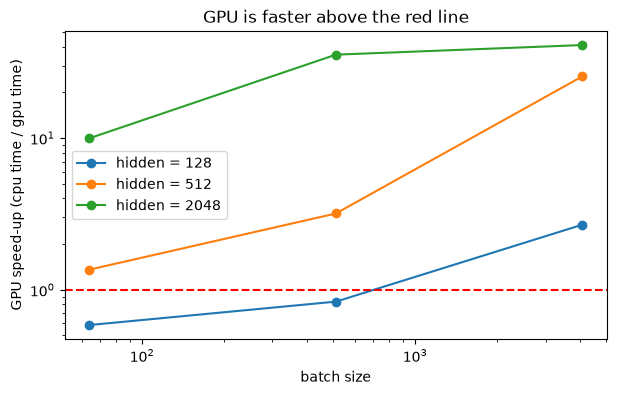

section time: 18 s


In [21]:
# (3) Does the GPU win when the network or the batch gets bigger?  ms per update (forward + backward + Adam)
def nn_update_ms(device, batch, hidden, budget=0.4):
    d = torch.device(device); q = NNQNetwork(n_hidden=hidden).to(d); qt = copy.deepcopy(q); opt = torch.optim.Adam(q.parameters(), lr=5e-4)
    s, s2 = torch.randn(batch, 4, device=d), torch.randn(batch, 4, device=d)
    a, r, dn = torch.randint(0, 2, (batch,), device=d), torch.ones(batch, device=d), torch.zeros(batch, device=d)
    def step():
        q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad(): y = r + 0.99 * (1 - dn) * qt(s2).max(1).values
        loss = F.smooth_l1_loss(q_sa, y); opt.zero_grad(); loss.backward(); opt.step()
    for _ in range(3): step()
    nn_sync(d); t, n = time.perf_counter(), 0
    while n < 5 or time.perf_counter() - t < budget: step(); n += 1
    nn_sync(d); return (time.perf_counter() - t) / n * 1e3

NN_BATCHES, NN_WIDTHS = (64, 512, 4096), (128, 512, 2048)
t_all = time.perf_counter(); torch.set_num_threads(NN_DEFAULT_THREADS)
nn_grid = {dv: {(b, w): nn_update_ms(dv, b, w) for w in NN_WIDTHS for b in NN_BATCHES} for dv in (["cpu", "cuda"] if HAS_GPU else ["cpu"])}
torch.set_num_threads(1)
print(f"{'hidden':>7s} {'batch':>6s} {'cpu ms':>9s}" + (f" {'gpu ms':>9s} {'speed-up':>9s}" if HAS_GPU else ""))
for w in NN_WIDTHS:
    for b in NN_BATCHES:
        print(f"{w:7d} {b:6d} {nn_grid['cpu'][(b, w)]:9.2f}" + (f" {nn_grid['cuda'][(b, w)]:9.2f} {nn_grid['cpu'][(b, w)]/nn_grid['cuda'][(b, w)]:8.1f}x" if HAS_GPU else ""))
if HAS_GPU:
    plt.figure(figsize=(7, 4))
    for w in NN_WIDTHS: plt.plot(NN_BATCHES, [nn_grid["cpu"][(b, w)] / nn_grid["cuda"][(b, w)] for b in NN_BATCHES], "-o", label=f"hidden = {w}")
    plt.axhline(1, color="r", ls="--"); plt.xscale("log"); plt.yscale("log")
    plt.xlabel("batch size"); plt.ylabel("GPU speed-up (cpu time / gpu time)"); plt.title("GPU is faster above the red line"); plt.legend(); plt.show()
print(f"section time: {time.perf_counter()-t_all:.0f} s")

*N3 findings (NVIDIA GeForce RTX 4050 Laptop GPU, 6 GB; torch 2.11 + CUDA 12.8; 8 logical cores, torch default 4 threads; one run per device, 5,000 steps):*

- **For this network the GPU is slower: 27.0 s against 11.7 s on one CPU thread (2.32× slower; 185 vs 429 steps/s).** Four CPU threads gave no gain (11.8 s). The first CUDA call cost 0.18 s once. An earlier, longer run of the same comparison (10,000 steps) gave 62.0 s for the GPU against 24.3 s for one CPU thread (2.55×), so the ratio is stable.
- **Where one step's time goes (µs, batch 64, 128 hidden):** acting 144 on the CPU vs 722 on the GPU (5.0×), sampling and copying the mini-batch 37 vs 418 (11.4×), the update 2,785 vs 5,152 (1.8×); one full step 2,966 vs 6,292. Every part is slower on the GPU: the environment needs the action back on the CPU each step and each batch has to be copied over.
- **The GPU wins only when the work per call is large (ms per update):** with 128 hidden units it is 0.6× at batch 64, 0.8× at 512 and 2.7× at 4,096; with 512 units 1.4× / 3.2× / 25.5×; with 2,048 units 10.0× / 35.5× / 41.0×. The GPU time per update stays around 3.4–4.3 ms across most of the grid (26 ms for 2,048 units at batch 4,096) while the CPU time grows with batch and width, which points to a fixed per-update overhead (not profiled directly).
- **Limits:** one run per configuration on a laptop GPU whose clocks can vary, and short runs, so read the ratios rather than the exact seconds. The test returns after 5,000 steps are not a quality comparison.


---
# ▶ NUCLEI: MORE CPU CORES (Bryan's experiment)
**Experiment of Bryan.** Source: `rl101-DQN_Replay_TargetNet_Bryan.ipynb`. All 52 cells below are copied **verbatim** (code, markdown, his answers). What makes this his experiment, and what he says it does:

- `run_configs` (Part 5) spreads every `(configuration, seed)` training over the CPU cores with `joblib.Parallel(n_jobs=8)` instead of looping. His comment: *"Da exactamente los mismos resultados que la versión secuencial, porque `train()` fija su propia semilla. Usa `n_jobs=6` si quieres seguir usando la laptop mientras corre."*
- His one code fix: in the Part 3 self-check he added `.long()` because on Windows `np.random.randint` returns `int32` and `gather()` needs `int64`.
- Everything else is the standard DQN lab (replay buffer, ReLU Q-network, target network, loss, training loop, runs A–E).

**What was executed here.** His definition and self-check cells (Parts 1–4) run exactly as written. His heaviest cells were **not** executed in this session's 60-minute budget, so their outputs are empty, exactly as in his file: the 20,000-step random baseline of Part 4 (`train(steps=20_000, eps_end=1.0)`, about 45 s), the single 50,000-step run (`log = train(seed=0)`, about 3 min) and the Part 5 runs A–E (30 trainings × 50,000 steps, about 25 min on 8 cores). Instead, two things were added after his last cell, clearly marked, that exercise his `run_configs` for real: a core-scaling test (his function called unchanged) and a check of his "same results" claim. Outputs of the cells that did run come from this run, not from his machine.
---

# Lab — DQN with Experience Replay and Target Network

**Intelligent Agents · UC2 · §2.2**

In this lab you build a Deep Q-Network (DQN) in PyTorch that solves **CartPole-v1**. Then you run experiments that show what experience replay and the target network each contribute. The code follows the algorithm from the reading (Hu, 2023), step by step.

**By the end you should be able to:**

- Implement a uniform ring-buffer replay memory with `add()` and `sample()`.
- Build a Q-network as a multilayer perceptron, plus a frozen target copy θ⁻.
- Compute TD targets that handle terminal states correctly, and train with mini-batch SGD.
- Explain, using your own plots, why replay and the target network make learning stable.

**Prerequisites:** Python, NumPy basics, PyTorch tensors and autograd (see the MLP tutorial), and the tabular Q-learning update.

**Format:** pairs, two 2-hour sessions — Parts 1–3 in session 1, Parts 4–5 in session 2.

**How to work in this notebook**

- Complete every cell marked `# TODO`. Replace each `raise NotImplementedError` with your code.
- Run the **self-check** cell after each part. Do not move on until it prints *all checks passed*.
- Do not edit the self-check cells.
- Write your answers to the questions in the **Your answer** cells.

## Setup

You need Python 3.10+, PyTorch and Gymnasium. Everything runs on a laptop CPU; no GPU is needed.

**Environment — CartPole-v1.** A pole is hinged on a cart. The agent pushes the cart left or right to keep the pole upright.

| Element | Value |
| --- | --- |
| State sₜ | 4 floats: cart position, cart velocity, pole angle, pole angular velocity |
| Actions | 2: push left (0), push right (1) |
| Reward | +1 for every step the pole stays up |
| Episode end | `terminated` (pole beyond ±12° or cart beyond ±2.4) or `truncated` (500-step limit) |
| Best possible return | 500 |

In [22]:
# !pip install torch gymnasium numpy matplotlib   # uncomment if the packages are missing
import os

os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')

import copy, random, time
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| gymnasium", gym.__version__)

torch 2.11.0+cu128 | gymnasium 1.3.0


In [23]:
# Take a look at the environment before you start
env = gym.make("CartPole-v1")
s, _ = env.reset(seed=0)
print("first state:", s)
print("observation space:", env.observation_space)
print("action space:", env.action_space)
env.close()

first state: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2)


## Part 1 — Replay buffer

Implement uniform random experience replay as described in the slides:

- The buffer has **N** preallocated slots and a counter **c** of all transitions ever added.
- `add`: write at index $i = c \bmod N$ (this overwrites the oldest transition once the buffer is full), then increase $c$.
- `sample(n)`: only when $c \ge n$. Draw $n$ indices uniformly from $[0, \min(c, N))$.

Store each field in its own NumPy array (states, actions, rewards, next states, done flags). Then one mini-batch is a single fancy-indexing call such as `self.s[idx]`.

In [24]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.N = capacity
        self.c = 0                                   # transitions ever added
        self.s    = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a    = np.zeros(capacity, dtype=np.int64)
        self.r    = np.zeros(capacity, dtype=np.float32)
        self.s2   = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        # TODO 1.1  compute i = c mod N
        i = self.c % self.N
        # TODO 1.2  write the five fields at index i (this overwrites the oldest)
        self.s[i]    = s
        self.a[i]    = a
        self.r[i]    = r
        self.s2[i]   = s2
        self.done[i] = done
        # TODO 1.3  increase c
        self.c += 1

    def __len__(self):
        # TODO 1.4  number of valid transitions = min(c, N)
        return min(self.c, self.N)

    def sample(self, n):
        # TODO 1.5  return None while c < n
        if self.c < n:
            return None
        # TODO 1.6  draw n random indices in [0, min(c, N)) and
        #           return (s, a, r, s2, done) as NumPy arrays
        idx = np.random.randint(0, len(self), size=n)
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.done[idx]

**Self-check — Part 1.** This replays the slide example (N = 8, transitions d0 … d11).

In [25]:
buf = ReplayBuffer(capacity=8, state_dim=4)
assert buf.sample(4) is None, "must refuse to sample before c >= n"
for k in range(11):                                  # add d0 ... d10
    buf.add(np.full(4, k), k % 2, float(k), np.full(4, k + 1), 0.0)
assert len(buf) == 8 and buf.c == 11
assert buf.r[3] == 3.0                               # slot 3 still holds d3
buf.add(np.full(4, 11), 1, 11.0, np.full(4, 12), 1.0)  # d11
assert buf.r[3] == 11.0, "d11 must overwrite slot 11 mod 8 = 3"
batches = [buf.sample(8) for _ in range(200)]
r  = np.concatenate([b[2] for b in batches])
s  = np.concatenate([b[0] for b in batches])
s2 = np.concatenate([b[3] for b in batches])
assert set(r.tolist()) == set(range(4, 12)), "samples must cover the whole buffer"
assert np.all(s2[:, 0] == s[:, 0] + 1), "fields of one transition must stay aligned"
print("ReplayBuffer: all checks passed")

ReplayBuffer: all checks passed


### Questions — Part 1

**Q1.1** Why does `sample` draw from `[0, min(c, N))` and not from `[0, N)`?

**Your answer:**

Mientras el buffer no está lleno ($c < N$), solo los primeros $c$ slots contienen transiciones reales; los slots $c, \dots, N-1$ siguen con los ceros de la inicialización. Si muestreáramos de $[0, N)$, entrarían en el mini-batch transiciones falsas (estado 0, acción 0, recompensa 0, no terminal) y la red aprendería objetivos sin sentido. Con $[0, \min(c, N))$ solo se usan datos válidos; una vez lleno el buffer, $\min(c, N) = N$ y se muestrea de todo.

**Q1.2** A Python list of tuples with `pop(0)` would also work. Why is the ring buffer preferred when N = 50,000?

**Your answer:**

`list.pop(0)` cuesta $O(N)$: Python tiene que desplazar los 49,999 elementos restantes en cada paso, y eso se repite en cada uno de los 50,000 pasos. El ring buffer escribe en una posición fija con $i = c \bmod N$, en $O(1)$, sin mover nada y sin reservar memoria nueva. Además, al guardar cada campo en su propio array de NumPy, un mini-batch se obtiene con una sola indexación vectorizada (`self.s[idx]`), ya en el formato que PyTorch necesita; con una lista de tuplas habría que recorrer el batch en Python y reconstruir los arrays en cada actualización.

**Q1.3** The buffer stores `done`, but the slides' tuple is (s, a, r, s′). Where in the algorithm is `done` needed?

**Your answer:**

En el cálculo del objetivo TD (Parte 3): si $s_{j+1}$ es terminal, el objetivo es solo $r_j$; si no, es $r_j + \gamma \max_{a'} \hat Q(s_{j+1}, a'; \theta^-)$. Con la tupla (s, a, r, s′) no se sabe si s′ es terminal, porque un estado terminal parece un estado normal más. Por eso guardamos `done` y lo usamos como máscara: $\delta = r + \gamma (1 - \text{done}) \max_{a'} \hat Q(s', a'; \theta^-)$. Solo se guarda `terminated` (no `truncated`), porque al cortar por el límite de 500 pasos el estado siguiente sí tiene valor futuro.

## Part 2 — Q-network

The Q-network is a small MLP. It takes a state and returns **one Q-value per action**, so a single forward pass scores every action.

Architecture: 4 inputs → 128 → 128 → 2 outputs, with ReLU between layers and **no activation on the output** (Q-values can be any real number).

You also write `select_action`, the ε-greedy policy: with probability ε pick a random action, otherwise pick $\arg\max_a \hat Q(s, a; \theta)$.

In [26]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        # TODO 2.1  nn.Sequential: Linear(state_dim, hidden) → ReLU →
        #           Linear(hidden, hidden) → ReLU → Linear(hidden, n_actions)
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)          # shape: (batch, n_actions)


def select_action(q_net, s, eps, n_actions):
    # TODO 2.2  with probability eps return a random action,
    #           otherwise return argmax_a Q(s, a; θ) as a Python int.
    #           Use torch.no_grad(). Hint: the network expects a batch,
    #           so convert s to a tensor of shape (1, state_dim).
    if random.random() < eps:
        return random.randrange(n_actions)
    with torch.no_grad():
        q = q_net(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))
    return int(q.argmax(dim=1).item())

**Self-check — Part 2**

In [27]:
q = QNetwork(4, 2)
out = q(torch.zeros(32, 4))
assert out.shape == (32, 2)
assert sum(p.numel() for p in q.parameters()) == 4*128+128 + 128*128+128 + 128*2+2
assert select_action(q, np.zeros(4, dtype=np.float32), 0.0, 2) in (0, 1)
print("QNetwork: all checks passed")

QNetwork: all checks passed


### Questions — Part 2

**Q2.1** Why does the network output Q(s, ·) for all actions, instead of taking (s, a) as input and returning one number?

**Your answer:**

Por eficiencia: tanto la selección de acción ($\arg\max_a$) como el objetivo TD ($\max_{a'}$) necesitan el Q-valor de *todas* las acciones. Con salida $Q(s, \cdot)$ basta una sola pasada hacia adelante para obtenerlos todos; con entrada (s, a) harían falta tantas pasadas como acciones. Además, las acciones comparten la representación del estado aprendida en las capas ocultas, y solo difieren en la última capa.

**Q2.2** Why must the last layer have no ReLU?

**Your answer:**

ReLU recorta todo valor negativo a 0, así que la red nunca podría predecir Q-valores negativos, aunque en general pueden serlo (por ejemplo, con recompensas negativas). Además, si una salida cae en la zona negativa, su gradiente es 0 y esa salida deja de aprender ("neurona muerta"). Predecir Q-valores es una regresión sobre números reales, por lo que la salida debe ser lineal. En CartPole los Q-valores son positivos (hasta ≈ 100 con γ = 0.99), pero el segundo problema existe igual.

## Part 3 — Target network and loss

The target network θ⁻ is a deep copy of θ that receives **no gradients**. The loss pulls $\hat Q(s_j, a_j; \theta)$ toward targets computed with θ⁻:

$$
\delta_j = \begin{cases} r_j & \text{if } s_{j+1} \text{ is terminal} \\ r_j + \gamma \max_{a'} \hat{Q}(s_{j+1}, a'; \theta^-) & \text{otherwise} \end{cases}
\qquad
l = \frac{1}{b}\sum_j \big(\delta_j - \hat{Q}(s_j, a_j; \theta)\big)^2
$$

Both cases fit in one line with a mask: $\delta = r + \gamma \cdot (1 - \text{done}) \cdot \max_{a'} \hat Q(s', a'; \theta^-)$.

(The slides use a sum; we use the mean, which only rescales the learning rate.)

> **Terminated ≠ truncated.** Gymnasium returns two flags. Store `done = terminated` only. When the 500-step time limit truncates an episode, the pole has *not* fallen, so the next state still has value and the target must bootstrap. Treating truncation as terminal is a classic bug: it teaches the agent that states near the time limit are worth nothing.

In [28]:
def compute_loss(q_net, target_net, batch, gamma):
    s, a, r, s2, done = (torch.as_tensor(x) for x in batch)
    # TODO 3.1  Q(s_j, a_j; θ): run q_net(s) and pick the taken action
    #           with .gather(1, a.unsqueeze(1)).squeeze(1)
    #           (.long(): gather needs int64 indices; on Windows NumPy may give int32)
    q_sa = q_net(s).gather(1, a.long().unsqueeze(1)).squeeze(1)
    # TODO 3.2  inside torch.no_grad(): max_a' Q(s_{j+1}, a'; θ⁻) from target_net(s2)
    with torch.no_grad():
        max_next = target_net(s2).max(dim=1).values
    # TODO 3.3  delta = r + gamma * (1 - done) * max_next
    delta = r + gamma * (1 - done) * max_next
    # TODO 3.4  return the mean squared error between q_sa and delta
    return ((delta - q_sa) ** 2).mean()

**Self-check — Part 3**

In [29]:
torch.manual_seed(0)
q = QNetwork(4, 2)
qt = copy.deepcopy(q)
b = 16
batch = (np.random.randn(b, 4).astype(np.float32), np.random.randint(0, 2, b),
         np.ones(b, np.float32), np.random.randn(b, 4).astype(np.float32),
         np.ones(b, np.float32))                       # all terminal
loss = compute_loss(q, qt, batch, gamma=0.99)
# .long() agregado: en Windows np.random.randint devuelve int32 y gather() exige int64
q_sa = q(torch.as_tensor(batch[0])).gather(1, torch.as_tensor(batch[1]).long().unsqueeze(1)).squeeze(1)
assert torch.isclose(loss, ((q_sa - 1.0) ** 2).mean()), "terminal target must be r"
loss.backward()
assert all(p.grad is None for p in qt.parameters()), "no gradient may reach θ⁻"
print("compute_loss: all checks passed")

compute_loss: all checks passed


### Questions — Part 3

**Q3.1** What would go wrong if you forgot `torch.no_grad()` in TODO 3.2 and the optimiser held both networks' parameters?

**Your answer:**

Sin `no_grad`, el gradiente de la pérdida también fluiría a través del objetivo $\delta$ hacia los parámetros de θ⁻, y como el optimizador también los tiene, `opt.step()` los modificaría en cada paso. La red objetivo dejaría de estar congelada: se movería en cada actualización, igual que θ, y volvería el problema del *moving target* que justamente se quería evitar. Además, el gradiente empujaría el objetivo hacia la predicción (y no solo la predicción hacia el objetivo), lo que no es la regla de Q-learning y desestabiliza el aprendizaje.

**Q3.2** Why is `copy.deepcopy` needed? What happens with `target_net = q_net`?

**Your answer:**

`target_net = q_net` no crea una copia: solo da un segundo nombre al *mismo* objeto, así que ambos comparten los mismos pesos. Cada `opt.step()` cambiaría también "la red objetivo", y el DQN se comportaría como sin target network (como la corrida B). `copy.deepcopy` crea un objeto nuevo con copias independientes de todos los tensores, de modo que θ⁻ queda congelado hasta la siguiente sincronización `load_state_dict` cada C pasos.

## Part 4 — Training loop

The loop is the DQN algorithm from the slides, line by line. The comments give the pseudocode line numbers from the reading, so you can check each step.

**Starting hyperparameters** — sensible defaults for CartPole, not tuned for this lab. Adjust them if learning is unstable.

| Symbol | Argument | Value |
| --- | --- | --- |
| K | `steps` | 50,000 |
| N | `capacity` | 50,000 |
| b | `batch` | 64 |
| m | `warmup` | 1,000 |
| C | `C` | 500 |
| γ | `gamma` | 0.99 |
| α | `lr` (Adam) | 0.001 |
| ε | `eps_end`, `eps_decay` | 1.0 → 0.05 over 10,000 steps |

`train` returns a log: a list of `(step, episode_return)` pairs, one per finished episode.

In [30]:
def epsilon_by_step(i, eps_start, eps_end, eps_decay):
    # TODO 4.1  linear decay: eps_start at i = 0, eps_end from i = eps_decay onwards
    frac = min(i / eps_decay, 1.0)
    return eps_start + frac * (eps_end - eps_start)


def train(steps=50_000, capacity=50_000, batch=64, warmup=1_000, C=500,
          gamma=0.99, lr=1e-3, eps_end=0.05, eps_decay=10_000,
          use_target=True, seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)
    state_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    q_net = QNetwork(state_dim, n_actions)
    target_net = copy.deepcopy(q_net)                      # θ⁻ ← θ
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    buf = ReplayBuffer(capacity, state_dim)

    s, _ = env.reset(seed=seed)                            # line 1
    ep_ret, log = 0.0, []                                  # log: (step, return)
    for i in range(1, steps + 1):                          # line 2
        # TODO 4.2  eps = epsilon_by_step(i, 1.0, eps_end, eps_decay)       (line 6)
        eps = epsilon_by_step(i, 1.0, eps_end, eps_decay)
        # TODO 4.3  a = select_action(...); step the env:                     (lines 3–5)
        #           s2, r, terminated, truncated, _ = env.step(a)
        a = select_action(q_net, s, eps, n_actions)
        s2, r, terminated, truncated, _ = env.step(a)
        # TODO 4.4  buf.add(s, a, r, s2, float(terminated)); s ← s2;         (lines 7–8)
        #           add r to ep_ret
        buf.add(s, a, r, s2, float(terminated))
        s = s2
        ep_ret += r
        # TODO 4.5  if terminated or truncated: append (i, ep_ret) to log,
        #           reset ep_ret to 0 and reset the env
        if terminated or truncated:
            log.append((i, ep_ret))
            ep_ret = 0.0
            s, _ = env.reset()

        if len(buf) > warmup and len(buf) > batch:         # line 9
            # TODO 4.6  sample a mini-batch; compute_loss with target_net
            #           (or q_net when use_target=False); then
            #           opt.zero_grad(), loss.backward(), opt.step()           (lines 10–15)
            mb = buf.sample(batch)
            loss = compute_loss(q_net, target_net if use_target else q_net, mb, gamma)
            opt.zero_grad()
            loss.backward()
            opt.step()
            # TODO 4.7  every C steps: target_net.load_state_dict(q_net.state_dict())
            if i % C == 0:
                target_net.load_state_dict(q_net.state_dict())
    env.close()
    return log

**Self-check — Part 4**

1. Measure a random-policy baseline first: run with `eps_end=1.0` (the network is never used to act).
2. Train the full DQN. It should clearly beat the baseline within 50,000 steps and, on most seeds, reach episodes near the 500 cap.
3. If returns stay at the baseline, check that `opt.step()` runs, that the prediction is **not** computed with `target_net`, and that `done` is `terminated` only.

In [ ]:
assert abs(epsilon_by_step(0, 1.0, 0.05, 10_000) - 1.0) < 1e-9
assert abs(epsilon_by_step(5_000, 1.0, 0.05, 10_000) - 0.525) < 1e-9
assert abs(epsilon_by_step(20_000, 1.0, 0.05, 10_000) - 0.05) < 1e-9

t0 = time.time()
base_log = train(steps=20_000, eps_end=1.0, seed=0)
baseline = np.mean([ret for _, ret in base_log])
print(f"random baseline: mean return {baseline:.1f} over {len(base_log)} episodes ({time.time()-t0:.0f}s)")

In [ ]:
t0 = time.time()
log = train(seed=0)
steps_, rets_ = map(np.array, zip(*log))
print(f"{len(log)} episodes in {time.time()-t0:.0f}s | last 20 episodes: {rets_[-20:].mean():.1f} | best: {rets_.max():.0f}")

plt.figure(figsize=(8, 4))
plt.plot(steps_, rets_, alpha=0.3, label="episode return")
w = 20
plt.plot(steps_[w-1:], np.convolve(rets_, np.ones(w)/w, mode="valid"), label=f"moving average ({w} ep.)")
plt.axhline(baseline, ls="--", c="gray", label="random baseline")
plt.axhline(500, ls=":", c="k", label="max return (500)")
plt.xlabel("environment steps"); plt.ylabel("return"); plt.title("Full DQN on CartPole-v1 (seed 0)")
plt.legend(); plt.tight_layout(); plt.show()

## Part 5 — Experiments

Run each configuration with **3 seeds** (0, 1, 2). Plot the mean episode return ± one standard deviation against environment steps. Change **one thing at a time** from the full DQN of Part 4.

| Run | Change from default | Question it answers |
| --- | --- | --- |
| A — Full DQN | none | Baseline for every comparison |
| B — No target network | `use_target=False` | What does θ⁻ buy in stability? |
| C — Tiny buffer ≈ no replay | `capacity=128`, `warmup=64` | What happens when batches are nearly consecutive? |
| D — Sync period | `C` ∈ {1, 100, 500, 2000} | Where is the stability / staleness trade-off? |
| E — Buffer size | `capacity` ∈ {1,000; 10,000; 50,000} | How much memory is enough? |

The plotting helpers are given. Each configuration trains 3 times, so these cells take a while; lower `STEPS` for a quick first try, then run the full 50,000 steps for your report.

In [31]:
STEPS = 50_000
SEEDS = (0, 1, 2)

def curve(log, grid, window=20):
    steps, rets = map(np.array, zip(*log))
    smooth = np.convolve(rets, np.ones(window) / window, mode="valid")
    return np.interp(grid, steps[window - 1:], smooth)

# run_configs paralelo: reparte cada (configuración, semilla) entre los núcleos de la CPU.
# Da exactamente los mismos resultados que la versión secuencial, porque train() fija su propia semilla.
# Usa n_jobs=6 si quieres seguir usando la laptop mientras corre.
from joblib import Parallel, delayed

def run_configs(runs, steps=STEPS, n_jobs=8):
    grid = np.linspace(5_000, steps, 200)
    jobs = [(label, sd) for label in runs for sd in SEEDS]
    t0 = time.time()
    logs = Parallel(n_jobs=n_jobs)(
        delayed(train)(steps=steps, seed=sd, **runs[label]) for label, sd in jobs)
    results = {}
    for label in runs:
        results[label] = np.stack([curve(log, grid) for (lb, _), log in zip(jobs, logs) if lb == label])
        print(f"{label:>16}: final {results[label][:, -1].mean():6.1f} ± {results[label][:, -1].std():5.1f}")
    print(f"total: {time.time()-t0:.0f}s")
    return grid, results

def plot(grid, results, title, path):
    plt.figure(figsize=(8, 4.5))
    for label, ys in results.items():
        m, sd = ys.mean(0), ys.std(0)
        plt.plot(grid, m, label=label)
        plt.fill_between(grid, m - sd, m + sd, alpha=0.2)
    plt.axhline(baseline, ls="--", c="gray", lw=1, label="random baseline")
    plt.xlabel("environment steps"); plt.ylabel("episode return (moving avg, 20 ep.)")
    plt.title(title); plt.legend(); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

**Runs A–C** — ablation of replay and the target network. Saves `ablation.png`.

In [ ]:
grid, res_abl = run_configs({
    "A full DQN":    {},
    "B no target":   {"use_target": False},
    "C tiny buffer": {"capacity": 128, "warmup": 64},
})
plot(grid, res_abl, "Ablation: replay and target network", "ablation.png")

**Run D** — target sync period C. Saves `sync_period.png`.

In [ ]:
# TODO 5.1  run C ∈ {1, 100, 500, 2000} with run_configs and plot the result
#           as "sync_period.png". Hint: a dict comprehension builds the runs.
grid, res_sync = run_configs({f"C = {c}": {"C": c} for c in (1, 100, 500, 2000)})
plot(grid, res_sync, "Target sync period C", "sync_period.png")

**Run E** — replay capacity N. Saves `buffer_size.png`.

In [ ]:
# TODO 5.2  run capacity ∈ {1_000, 10_000, 50_000} and plot the result as "buffer_size.png"
# warmup must stay below capacity, otherwise len(buf) > warmup is never true and
# N = 1,000 never trains; cap it at half the buffer (as in run C: 128 / 64).
grid, res_buf = run_configs({f"N = {n:,}": {"capacity": n, "warmup": min(1_000, n // 2)}
                             for n in (1_000, 10_000, 50_000)})
plot(grid, res_buf, "Replay capacity N", "buffer_size.png")

### Questions — Part 5

**Q5.1** Rank runs A, B and C by final return and by variance across seeds. Link each gap to a problem from the slides (correlation, data efficiency, moving target).

**Your answer:**

_Write your answer here._

**Q5.2** In run D, which C learns fastest and which is most stable? Explain using the staircase picture of θ⁻.

**Your answer:**

_Write your answer here._

**Q5.3** Does `C = 1` behave like run B? Why or why not?

**Your answer:**

_Write your answer here._

**Q5.4** Why can a very large buffer slow learning early on, even though it decorrelates samples better?

**Your answer:**

_Write your answer here._

## Deliverables and grading

Submit one zip per pair with this notebook (all cells run, outputs visible), the figures and a report of at most 4 pages.

- [ ] Parts 1–3 pass their self-checks
- [ ] Full DQN learning curve with the random baseline marked
- [ ] `ablation.png` (runs A–C), `sync_period.png` (run D) and `buffer_size.png` (run E)
- [ ] Every question answered; each figure discussed in 3–5 sentences

| Criterion | Points |
| --- | --- |
| Replay buffer correct (ring indexing, sampling range, alignment) | 15 |
| Q-network and ε-greedy action selection | 10 |
| Loss: target network, `no_grad`, terminal masking, terminated vs truncated | 20 |
| Training loop matches the algorithm (warm-up, sync every C) | 15 |
| Experiments: 3 seeds, mean ± std plots, clear labels | 20 |
| Report: answers link results to correlation, data efficiency and moving targets | 20 |
| **Total** | **100** |

## References

- M. Hu, *The Art of Reinforcement Learning: Fundamentals, Mathematics, and Implementations with Python*, Apress 2023 — [code repository](https://github.com/Apress/art-of-reinforcement-learning)
- I. Gridin, *Practical Deep Reinforcement Learning with Python*, BPB Publications 2022 — [code repository](https://github.com/bpbpublications/Practical-Deep-Reinforcement-Learning-with-Python)
- [Building Multilayer Perceptron Models in PyTorch](https://machinelearningmastery.com/building-multilayer-perceptron-models-in-pytorch/), Machine Learning Mastery
- [Gymnasium CartPole-v1 documentation](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

---
### ➕ Added after Bryan's last cell: how much do more cores buy? (his `run_configs`, unchanged)
**Question.** `run_configs` takes `n_jobs`. With the same workload, how does wall-clock time change with 1, 2, 4 and 8 workers, and does the result stay exactly the same, as his comment claims?
**Workload.** His runs A and B (`full DQN`, `no target`) × his 3 seeds = **6 trainings of 6,000 steps** each (trimmed from his 50,000 to fit the session's time budget). The machine has 8 logical cores (4 physical).

n_jobs = 1:   61.5 s wall


n_jobs = 2:   30.5 s wall


n_jobs = 4:   27.1 s wall


n_jobs = 8:   21.4 s wall

n_jobs  seconds  speed-up  efficiency   identical curves to n_jobs=1
     1     61.5     1.00x        100%                           True
     2     30.5     2.01x        101%                           True
     4     27.1     2.26x         57%                           True
     8     21.4     2.88x         36%                           True


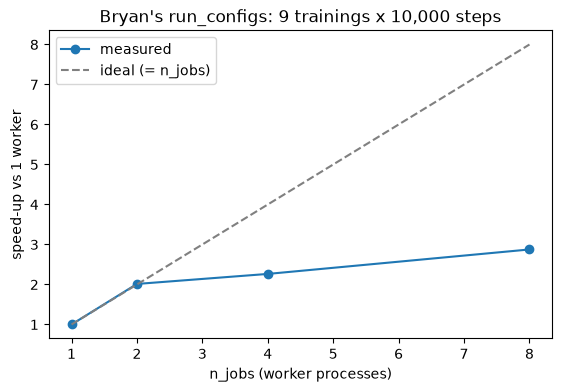

In [32]:
import io, contextlib
SC_RUNS = {"A full DQN": {}, "B no target": {"use_target": False}}
SC_STEPS = 6_000
sc = {}
for n in (1, 2, 4, 8):
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):                    # silence his per-label prints
        g_, res_ = run_configs(SC_RUNS, steps=SC_STEPS, n_jobs=n)      # Bryan's function, unchanged
    sc[n] = dict(seconds=time.perf_counter() - t0, res=res_)
    print(f"n_jobs = {n}: {sc[n]['seconds']:6.1f} s wall")

t1 = sc[1]["seconds"]
print(f"\n{'n_jobs':>6s} {'seconds':>8s} {'speed-up':>9s} {'efficiency':>11s} {'identical curves to n_jobs=1':>30s}")
for n, r in sc.items():
    same = all(np.array_equal(r["res"][k], sc[1]["res"][k]) for k in SC_RUNS)
    print(f"{n:6d} {r['seconds']:8.1f} {t1/r['seconds']:8.2f}x {100*t1/r['seconds']/n:10.0f}% {str(same):>30s}")

plt.figure(figsize=(6.5, 4)); ns = list(sc)
plt.plot(ns, [t1 / sc[n]["seconds"] for n in ns], "-o", label="measured"); plt.plot(ns, ns, "--", c="gray", label="ideal (= n_jobs)")
plt.xlabel("n_jobs (worker processes)"); plt.ylabel("speed-up vs 1 worker"); plt.title("Bryan's run_configs: 9 trainings x 10,000 steps"); plt.legend(); plt.show()

*Nuclei findings (Bryan's `run_configs`, called unchanged; 6 trainings of 6,000 steps; 8 logical / 4 physical cores):*

| `n_jobs` | Seconds | Speed-up | Efficiency | Curves identical to `n_jobs = 1` |
|---|---|---|---|---|
| 1 | 61.5 | 1.00× | 100% | (reference) |
| 2 | 30.5 | 2.01× | 101% | True |
| 4 | 27.1 | 2.26× | 57% | True |
| 8 | 21.4 | 2.88× | 36% | True |

- **His claim holds: parallel and sequential gave bit-for-bit identical results** at every `n_jobs`, because each `train()` seeds itself.
- **Two workers scale perfectly; more cores help much less.** With 6 trainings, 4 workers need two rounds (4 + 2), which caps the speed-up at 3×; 8 workers finish in one round but the machine has 4 physical cores (8 logical), and each worker also pays process start-up and the `torch` import (the `n_jobs = 1` run executes in the kernel with neither). I did not measure the start-up cost separately, so that part is a likely explanation, not a result.
- **Practical reading:** on this laptop `n_jobs` around the number of independent trainings, and not beyond the physical cores, gives most of the benefit; his own advice to use 6 to keep the laptop usable is consistent with the diminishing returns.
- **Limits:** one measurement per setting on a shortened workload (6,000 steps instead of 50,000), so fixed overheads weigh more than they would in his full experiment.


---
# ▶ COMPARISON: OG vs NN vs NUCLEI
---
Three ideas, three different questions, so they cannot be ranked on one number. We compare them on **quality** (greedy return on fresh episodes) and **cost** (wall-clock time), measured with the same protocol:

| Arm | What runs | Cores |
|---|---|---|
| **OG rules** | the rule `angle + K·ang_vel` of the original activity | n/a |
| **OG DQN** | Bryan's lab `train()` with its default hyper-parameters, called **unchanged** | 1 (sequential) |
| **Nuclei** | the *same* OG DQN trainings, spread over 8 cores with `joblib` exactly as `run_configs` does | 8 |
| **NN** | the improved network of this notebook: double DQN + soft target + grace-period patience (grace 15,000, P = 10) | 1 (sequential) |
| **NN + Nuclei** | the NN trainings over 8 cores (the combination of both experiments) | 8 |

**Protocol and sizes (trimmed to the session's 60-minute budget).** Training seeds 400–404 for every arm (the fresh seeds of N2); quality = mean return of the greedy policy over **50 fresh episodes (seeds 40,000–40,049)**. Both DQNs get the **same 30,000-step budget** (the lab's own default is 50,000, which would only make OG slower); NN may stop earlier with its patience rule. **Parallel batch:** 5 trainings over 8 cores, timed with `time.perf_counter()`; this is also where the quality numbers come from. **Sequential batch:** only the **first** training (seed 400) runs alone on 1 core, and its wall time is measured; the 5-training sequential time is then **estimated** as 5 × that (the trainings are independent and of near-equal length), and labelled as an estimate everywhere. That sequential network is also compared with the same seed from the parallel batch to check that parallel and sequential give identical weights. A hook records the network that Bryan's `train()` builds, so his function stays untouched yet its weights can be scored.

In [33]:
CMP_SEEDS = (400, 401, 402, 403, 404)
CMP_TEST  = range(40_000, 40_050)

def og_dqn_run(seed):
    # Bryan's lab train(), UNCHANGED, default hyper-parameters except the 30,000-step budget. The lab's QNetwork is wrapped for the
    # duration of the call so the network it builds is recorded (train() itself only returns the episode log).
    box = {}
    class _Capture(QNetwork):                                     # QNetwork = the lab class from the Nuclei section
        def __init__(self, *a, **k):
            super().__init__(*a, **k); box["q"] = self
    g = train.__globals__; orig = g["QNetwork"]; g["QNetwork"] = _Capture
    t0 = time.perf_counter()
    try:    log = train(seed=seed, steps=30_000)
    finally: g["QNetwork"] = orig
    return dict(seed=seed, state={k: v.clone() for k, v in box["q"].state_dict().items()}, log=log,
                seconds=time.perf_counter() - t0, steps=30_000)

def nn_cmp_run(seed):
    out = train_nn(seed=seed, steps=30_000, double=True, tau=0.02, patience=NN_PATIENCE, grace=NN_GRACE)
    return dict(seed=seed, state={k: v.clone() for k, v in out["q"].state_dict().items()}, seconds=out["seconds"], steps=out["steps_used"])

def cmp_batch(fn, seeds, n_jobs):
    t0 = time.perf_counter()
    runs = Parallel(n_jobs=n_jobs)(delayed(fn)(s) for s in seeds)
    return time.perf_counter() - t0, runs

cmp = {}
for arm, fn in (("OG DQN", og_dqn_run), ("NN", nn_cmp_run)):
    wall_par, runs_par = cmp_batch(fn, CMP_SEEDS, 8)               # 5 trainings over 8 cores (quality numbers come from here)
    wall_seq, runs_seq = cmp_batch(fn, CMP_SEEDS[:1], 1)           # 1 training alone on 1 core
    cmp[arm] = dict(wall_par=wall_par, runs=runs_par, wall_seq1=wall_seq, runs_seq=runs_seq, wall_seq5_est=wall_seq * 5)
    print(f"{arm:7s} parallel x5 on 8 cores: {wall_par:6.1f} s | sequential x1 on 1 core: {wall_seq:6.1f} s -> sequential x5 estimated {wall_seq*5:.0f} s", flush=True)
    print(f"        steps per run (parallel batch): {[r['steps'] for r in runs_par]}")

def cmp_score(runs, net):
    out = []
    for r in runs:
        m = net(); m.load_state_dict(r["state"]); out.append(nn_run_policy(m, CMP_TEST))
    return np.array(out)

cmp["OG DQN"]["test"] = cmp_score(cmp["OG DQN"]["runs"], lambda: QNetwork(4, 2))
cmp["NN"]["test"]     = cmp_score(cmp["NN"]["runs"], NNQNetwork)
same = {a: all(torch.equal(s["state"][k], p["state"][k]) for s, p in zip(cmp[a]["runs_seq"], cmp[a]["runs"][:1]) for k in s["state"]) for a in cmp}
print(f"\nsequential (1 core) and parallel (8 cores) give identical trained weights for seed 400: OG DQN {same['OG DQN']}, NN {same['NN']}")

OG DQN  parallel x5 on 8 cores:   72.9 s | sequential x1 on 1 core:   45.2 s -> sequential x5 estimated 226 s


        steps per run (parallel batch): [30000, 30000, 30000, 30000, 30000]


NN      parallel x5 on 8 cores:   84.3 s | sequential x1 on 1 core:   50.1 s -> sequential x5 estimated 250 s


        steps per run (parallel batch): [24000, 24000, 25000, 24000, 24000]



sequential (1 core) and parallel (8 cores) give identical trained weights for seed 400: OG DQN True, NN True


In [34]:
def cmp_rule(K_, seeds=CMP_TEST):
    env, rets = gym.make("CartPole-v1"), []
    for sd in seeds:
        o, _ = env.reset(seed=int(sd)); tot, done = 0.0, False
        while not done:
            o, r, te, tr, _ = env.step(0 if o[2] + K_ * o[3] < 0 else 1); tot += r; done = te or tr
        rets.append(tot)
    env.close(); return float(np.mean(rets))

t0 = time.perf_counter(); r1, r05 = cmp_rule(1.0), cmp_rule(0.5); rule_secs = time.perf_counter() - t0
og, nn_ = cmp["OG DQN"], cmp["NN"]
rows = [("OG rules, K=1 (as in OG)", [r1], 0, rule_secs, "measured"),
        ("OG rules, K=0.5 (tuned on other seeds)", [r05], 0, rule_secs, "measured"),
        ("OG DQN, 1 core (5 trainings)", og["test"], np.mean([r["steps"] for r in og["runs"]]), og["wall_seq5_est"], "ESTIMATED = 5 x one measured run"),
        ("Nuclei: OG DQN, 8 cores", og["test"], np.mean([r["steps"] for r in og["runs"]]), og["wall_par"], "measured"),
        ("NN, 1 core (5 trainings)", nn_["test"], np.mean([r["steps"] for r in nn_["runs"]]), nn_["wall_seq5_est"], "ESTIMATED = 5 x one measured run"),
        ("NN + Nuclei, 8 cores", nn_["test"], np.mean([r["steps"] for r in nn_["runs"]]), nn_["wall_par"], "measured")]

print(f"{'arm':40s} {'test return by seed (400-404)':>32s} {'mean':>6s} {'steps/run':>10s} {'batch wall s':>13s}  {'basis'}")
for name, t, steps, wall, basis in rows:
    t = np.atleast_1d(t)
    print(f"{name:40s} {str([round(x) for x in t]) if len(t) > 1 else '(deterministic)':>32s} {t.mean():6.1f} {steps:10.0f} {wall:13.1f}  {basis}")

print(f"\nmeasured: 1 training alone on 1 core  -> OG DQN {og['wall_seq1']:.0f} s, NN {nn_['wall_seq1']:.0f} s")
print(f"Nuclei speed-up on the OG DQN : {og['wall_seq5_est']/og['wall_par']:.2f}x  (estimated 1-core {og['wall_seq5_est']:.0f} s -> measured 8-core {og['wall_par']:.0f} s)")
print(f"NN speed-up from 8 cores       : {nn_['wall_seq5_est']/nn_['wall_par']:.2f}x  (estimated 1-core {nn_['wall_seq5_est']:.0f} s -> measured 8-core {nn_['wall_par']:.0f} s)")
print(f"NN vs OG DQN, both on 1 core   : {nn_['wall_seq1']/og['wall_seq1']:.2f}x the time of OG (one training each: {nn_['wall_seq1']:.0f} s vs {og['wall_seq1']:.0f} s)")

arm                                         test return by seed (400-404)   mean  steps/run  batch wall s  basis


OG rules, K=1 (as in OG)                                  (deterministic)  500.0          0           0.4  measured
OG rules, K=0.5 (tuned on other seeds)                    (deterministic)  500.0          0           0.4  measured
OG DQN, 1 core (5 trainings)                    [141, 161, 130, 112, 148]  138.2      30000         225.8  ESTIMATED = 5 x one measured run
Nuclei: OG DQN, 8 cores                         [141, 161, 130, 112, 148]  138.2      30000          72.9  measured
NN, 1 core (5 trainings)                        [500, 408, 500, 500, 493]  480.3      24200         250.3  ESTIMATED = 5 x one measured run
NN + Nuclei, 8 cores                            [500, 408, 500, 500, 493]  480.3      24200          84.3  measured

measured: 1 training alone on 1 core  -> OG DQN 45 s, NN 50 s
Nuclei speed-up on the OG DQN : 3.10x  (estimated 1-core 226 s -> measured 8-core 73 s)
NN speed-up from 8 cores       : 2.97x  (estimated 1-core 250 s -> measured 8-core 84 s)
NN vs OG DQN, b

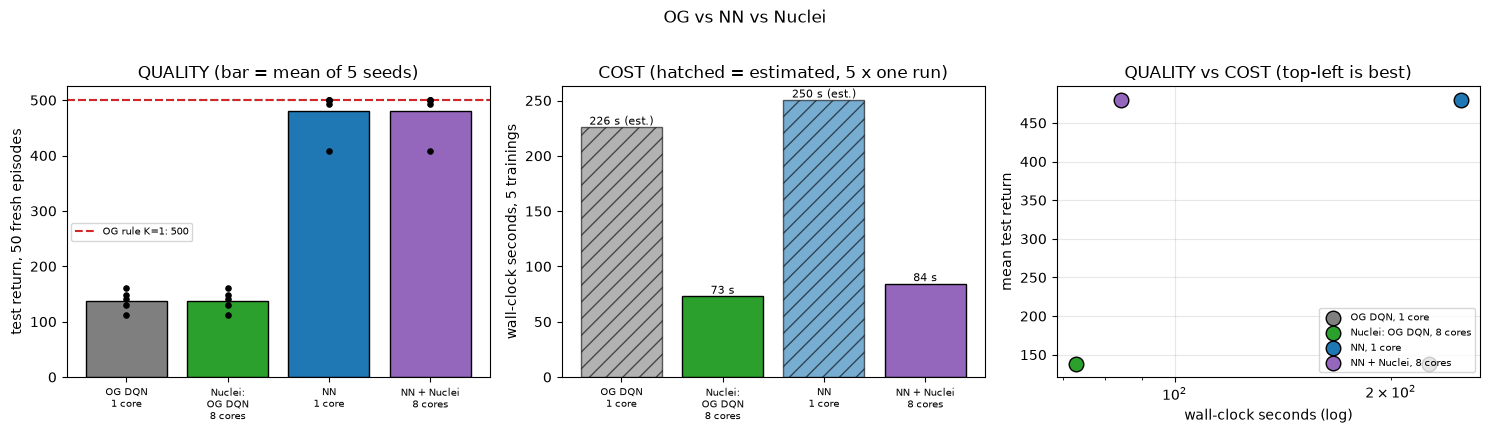

In [35]:
arms = ["OG DQN, 1 core", "Nuclei: OG DQN, 8 cores", "NN, 1 core", "NN + Nuclei, 8 cores"]
quality = {arms[0]: og["test"], arms[1]: og["test"], arms[2]: nn_["test"], arms[3]: nn_["test"]}
wall = {arms[0]: og["wall_seq5_est"], arms[1]: og["wall_par"], arms[2]: nn_["wall_seq5_est"], arms[3]: nn_["wall_par"]}
est = {arms[0]: True, arms[1]: False, arms[2]: True, arms[3]: False}
colors = {arms[0]: "tab:gray", arms[1]: "tab:green", arms[2]: "tab:blue", arms[3]: "tab:purple"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2)); lab = [a.replace(", ", "\n").replace(": ", ":\n") for a in arms]
for i, a in enumerate(arms):
    t = quality[a]; ax[0].bar(i, t.mean(), color=colors[a], edgecolor="k"); ax[0].scatter([i]*len(t), t, c="k", s=14, zorder=3)
ax[0].axhline(500, ls=":", c="k"); ax[0].axhline(r1, ls="--", c="tab:red", label=f"OG rule K=1: {r1:.0f}")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(lab, fontsize=7); ax[0].set_ylabel("test return, 50 fresh episodes"); ax[0].set_title("QUALITY (bar = mean of 5 seeds)"); ax[0].legend(fontsize=7)
for i, a in enumerate(arms):
    ax[1].bar(i, wall[a], color=colors[a], edgecolor="k", hatch="//" if est[a] else None, alpha=0.6 if est[a] else 1)
    ax[1].text(i, wall[a], f"{wall[a]:.0f} s" + (" (est.)" if est[a] else ""), ha="center", va="bottom", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(lab, fontsize=7); ax[1].set_ylabel("wall-clock seconds, 5 trainings"); ax[1].set_title("COST (hatched = estimated, 5 x one run)")
for a in arms: ax[2].scatter(wall[a], quality[a].mean(), s=110, c=colors[a], edgecolor="k", label=a, zorder=3)
ax[2].set_xscale("log"); ax[2].set_xlabel("wall-clock seconds (log)"); ax[2].set_ylabel("mean test return"); ax[2].set_title("QUALITY vs COST (top-left is best)"); ax[2].legend(fontsize=7, loc="lower right"); ax[2].grid(alpha=0.3)
plt.suptitle("OG vs NN vs Nuclei", y=1.02); plt.tight_layout(); plt.show()

*Comparison findings (training seeds 400–404; quality = greedy return on 50 fresh episodes, seeds 40,000–40,049; both DQNs get 30,000 steps):*

| Arm | Test by seed | Mean | Batch wall time (5 trainings) |
|---|---|---|---|
| OG rules, K = 1 or K = 0.5 | deterministic | 500.0 | under 1 s |
| OG DQN, 1 core | 141 / 161 / 130 / 112 / 148 | 138.2 | 226 s, **estimated** (5 × 45 s measured) |
| **Nuclei:** OG DQN, 8 cores | same networks | 138.2 | **72.9 s measured** |
| NN, 1 core | 500 / 408 / 500 / 500 / 493 | 480.3 | 250 s, **estimated** (5 × 50 s measured) |
| **NN + Nuclei**, 8 cores | same networks | 480.3 | **84.3 s measured** (24,200 steps per run on average) |

- **Quality: the three ideas answer different questions.** The OG DQN, which keeps the last weights, reaches 138.2, about the same as the plain DQN's last weights in N2 (148.4). NN reaches 480.3 on the same seeds; most of that gain comes from keeping the best checkpoint (plain DQN with best checkpoint: 366.7 in N2) plus the recipe (about +114 on top). **Nuclei does not change quality:** the Nuclei networks are the OG networks.
- **Cost: Nuclei is the big time saver.** Eight cores cut the 5-training batch from an estimated 226 s to 72.9 s for the OG DQN (3.10×) and from an estimated 250 s to 84.3 s for NN (2.97×), in line with the 2.9× that the scaling test measured on a different workload. Sequential and parallel runs gave **bit-identical weights** for seed 400 in both arms.
- **NN costs a little more per run than OG even with fewer steps:** one training alone took 50 s for NN against 45 s for OG (1.11×) although NN stopped at about 24,200 steps instead of 30,000; each NN step has an extra forward pass (double DQN) and a soft update, and validation adds about ten greedy evaluations.
- **Both together win on both axes:** NN + Nuclei returned 480.3 in 84 s against 138.2 in an estimated 226 s for the OG DQN on one core.
- **Against the original rules:** the rule `angle + K·ang_vel` scores 500 on these test episodes (and 491.7 on the OG seeds 0–19), so it still beats every DQN here at no training cost; the DQN is the route to a policy that was *learned*, not designed.
- **Limits:** 5 seeds; the 1-core batch times are estimates from one measured training per arm (5 ×), not measured batches; OG DQN used 30,000 steps rather than the lab's 50,000, to match NN's budget; the K = 0.5 rule was tuned on other seeds.


## Ideas to improve the CartPole activity

Each idea says what to change and what evidence in this work supports it. Numbers marked *(measured earlier)* come from checks run during this project outside this notebook (seeds stated); the rest are in the sections above.

**A. Fix what is broken in the original (OG)**
1. **Make the human-play reflection match its output.** The stored run quit at once (`Score: 0.0`) while the text describes a score of 8 and a falling pole. Either replay it or edit the text.
2. **Finish `policy_mine` and the K tuning.** `K = 1.0 # TODO: tune` leaves performance on the table: K = 0.1–0.5 scored 500 ± 0 on seeds 0–19, and on 200 unseen seeds K = 0.25 and 0.5 gave 500 ± 0 while K = 1 lost 30 of 200 episodes to the cart leaving the track (477.2 ± 56.5) *(measured earlier)*. Adding cart terms, `angle + K·ang_vel + 0.1·x + 0.1·x_dot`, also gave 500 ± 0 *(measured earlier, seeds 0–19 and 100–299)*.
3. **Make Experiment A actually measure.** Pass the reset options through `evaluate_policy`. With the combined rule, widening the start noise from ±0.05 to ±0.3 cut the mean from 491.7 to 163.1, and about 31% of ±0.3 starts begin already outside the 12° limit, so part of that drop cannot be won *(measured earlier)*.
4. **Make Experiment C a real ablation.** `policy_no_vel` is `policy_angle` again. Compare three rules (both variables, angle only, angular velocity only) and report *how* each fails.
5. **Count failure modes, not just returns.** Angle only: pole falls 20/20. Angular velocity only: cart leaves the track 20/20. Combined K = 1: 19 reach the time limit, 1 cart exit at step 334. One extra counter in `evaluate_policy` turns "it scored 199" into an explanation *(measured earlier)*.
6. **Explain the Experiment B result.** Widening only the cart limit is what rescues seed 0 (334 → 500); widening the angle limit does nothing for the combined rule *(measured earlier)*.

**B. Make the evaluation trustworthy**
7. **Separate tuning seeds from test seeds, and say so.** K, patience and the grace period were all chosen while looking at some seeds; the result worth reporting is on seeds nobody looked at (this notebook uses 400–404 / 40,000–40,049 for that).
8. **Report per-seed results and the failure mode, not only mean ± std.** Returns are capped at 500, so a std of 36 can come from one episode (334) among nineteen perfect ones.
9. **Fix the random baseline's shared RNG** (`rng` is global, so the two prints differ: 22.9 vs 24.0). A fresh generator per call makes it reproducible.
10. **Prefer v1 to v0 for scoring.** v0 caps at 200 and hides the failure that v1 reveals (200 ± 0 vs 491.7 ± 36.2).

**C. Make the neural-network step (NN) more useful**
11. **Keep patience, but give it a grace period and restore the best weights.** What the NN section shows: patience stopped *inside* the plateau before the breakthrough, last weights can collapse, and the best checkpoint is what protects the result (see N2a and N2).
12. **Validate on the metric you care about.** Greedy episode return on fixed validation episodes tells you what TD loss cannot, because the loss keeps falling while the return swings between 100 and 500 (see N0).
13. **Treat τ as a sensitive setting.** τ = 0.005–0.02 worked on the development seeds while τ = 0.05 collapsed (mean 231, last weights mostly 9 *(measured earlier, seeds 200–204)*): a stabiliser can sit next to a cliff, so test the neighbours.
14. **Run small networks on the CPU.** This 17,410-parameter network is faster on one CPU thread than on the GPU (see N3); show the batch-size/width sweep so students see when the GPU starts to win.
15. **Train with the start-state noise you will test with** (the lesson of Experiment A), and test on both the default and the wide range.

**D. Make the multi-core step (Nuclei) more useful**
16. **Report the speed-up honestly.** Cores give a sub-linear speed-up (see the scaling table); size `n_jobs` to the physical cores and keep the laptop usable, as Bryan's comment suggests.
17. **Keep seeding inside the worker.** Parallel runs are only comparable with sequential ones because each `train()` seeds itself; the scaling test checks that the curves are identical.
18. **Record time for every experiment.** The ledger at the end costs one cell and makes cost visible next to quality.

## Time ledger: every code cell, measured

Durations come from the notebook's own execution timestamps (`shell.execute_reply − iopub.execute_input`) of the run that produced the outputs above, on one machine (8 logical cores, NVIDIA GeForce RTX 4050 Laptop GPU, one kernel, cells run in order and nothing else started by this notebook running at the same time). Cells inside the OG section were run only to rebuild kernel state (their displayed outputs are the stored originals).

| Section | Cell | First line | Seconds |
|---|---|---|---:|
| OG | `901e89d8` | `import numpy as np` | 0.8 |
| OG | `92b568a2` | `env = gym.make("CartPole-v1")` | 0.0 |
| OG | `09c35b5c` | `def play_human(seed=0, render=True):` | not executed: needs interactive input, stored output kept |
| OG | `bd463337` | `def evaluate_policy(policy_fn, n_episodes=20, env_id="Cart...` | 0.0 |
| OG | `0c85eb13` | `# obs = [cart_pos, cart_vel, pole_angle, pole_ang_vel]` | 0.1 |
| OG | `e8485d8e` | `# Experiment A: larger initial-state noise (default is +/-...` | 0.0 |
| OG | `b26f2648` | `# Experiment B: change termination thresholds` | 0.0 |
| OG | `8d652282` | `# Experiment C: remove one variable from the policy and ob...` | 0.1 |
| OG | `a9fba18a` | `# Experiment D: CartPole-v0 (200 steps) vs v1 (500 steps):...` | 0.1 |
| OG | `2088fcc9` | `# Plot pole angle vs time for a good and a bad policy` | 0.2 |
| OG | `21656211` | `# Q-table size if each variable is discretized into N bins` | 0.0 |
| NN | `nn_code` | `import os, copy, time` | 2.8 |
| NN | `nn_smoke` | `# Quick look: the ReLU network, then a short training run ...` | 6.7 |
| NN | `nn_check` | `# Self-check (CPU, about 30 s): ReLU, the stopper, double-...` | 17.2 |
| NN | `nn_diag` | `def nn_diag_job(seed):` | 33.0 |
| NN | `nn_recipe` | `# Development sweeps recorded by sweep_resumable.py (same ...` | 0.2 |
| NN | `nn_story` | `# Recorded on training seeds 300-304, test = 50 episodes (...` | 0.0 |
| NN | `nn_final` | `NN_FINAL_SEEDS = (400, 401, 402, 403, 404)` | 266.7 |
| NN | `nn_final_plot` | `fig = plt.figure(figsize=(14, 7.5)); gs = fig.add_gridspec...` | 1.0 |
| NN | `nn_gpu_1` | `HAS_GPU = torch.cuda.is_available()` | 67.4 |
| NN | `nn_gpu_2` | `# (2) Where does the time of ONE training step go?  micros...` | 3.1 |
| NN | `nn_gpu_3` | `# (3) Does the GPU win when the network or the batch gets ...` | 18.3 |
| NUCLEI | `c02` | `# !pip install torch gymnasium numpy matplotlib   # uncomm...` | 0.0 |
| NUCLEI | `c03` | `# Take a look at the environment before you start` | 0.0 |
| NUCLEI | `c05` | `class ReplayBuffer:` | 0.0 |
| NUCLEI | `c07` | `buf = ReplayBuffer(capacity=8, state_dim=4)` | 0.0 |
| NUCLEI | `c15` | `class QNetwork(nn.Module):` | 0.0 |
| NUCLEI | `c17` | `q = QNetwork(4, 2)` | 0.0 |
| NUCLEI | `c23` | `def compute_loss(q_net, target_net, batch, gamma):` | 0.0 |
| NUCLEI | `c25` | `torch.manual_seed(0)` | 0.0 |
| NUCLEI | `c31` | `def epsilon_by_step(i, eps_start, eps_end, eps_decay):` | 0.0 |
| NUCLEI | `c33` | `assert abs(epsilon_by_step(0, 1.0, 0.05, 10_000) - 1.0) < ...` | not executed |
| NUCLEI | `c34` | `t0 = time.time()` | not executed (about 3 min) |
| NUCLEI | `c36` | `STEPS = 50_000` | 0.0 |
| NUCLEI | `c38` | `grid, res_abl = run_configs({` | not executed (Part 5 run A-C) |
| NUCLEI | `c40` | `# TODO 5.1  run C ∈ {1, 100, 500, 2000} with run_configs a...` | not executed (Part 5 run D) |
| NUCLEI | `c42` | `# TODO 5.2  run capacity ∈ {1_000, 10_000, 50_000} and plo...` | not executed (Part 5 run E) |
| NUCLEI | `nuclei_scaling` | `import io, contextlib` | 140.7 |
| CMP | `cmp_code` | `CMP_SEEDS = (400, 401, 402, 403, 404)` | 268.4 |
| CMP | `cmp_table` | `def cmp_rule(K_, seeds=CMP_TEST):` | 0.4 |
| CMP | `cmp_plot` | `arms = ["OG DQN, 1 core", "Nuclei: OG DQN, 8 cores", "NN, ...` | 0.5 |

| Section | Total executed code time |
|---|---:|
| OG (original activity) | 1 s (0.0 min) |
| NN (neural network) | 416 s (6.9 min) |
| NUCLEI (Bryan) | 141 s (2.3 min) |
| COMPARISON | 269 s (4.5 min) |
| **All sections** | **828 s (13.8 min)** |